<a href="https://colab.research.google.com/github/bdong2005/san-diego-general-fund-analysis/blob/main/Stat_420_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# # ============================================================
# # SAVE PROFILING RESULTS TO A SEPARATE EXCEL FILE
# # ============================================================

# # Create a table containing missing-value details
# missing_details = []

# for name, df in datasets.items():

#     for column in df.columns:

#         missing_count = df[column].isna().sum()

#         if missing_count > 0:
#             missing_details.append({
#                 "Dataset": name,
#                 "Column": column,
#                 "Missing Values": missing_count,
#                 "Missing Percentage": round(
#                     (missing_count / len(df)) * 100,
#                     2
#                 )
#             })

# missing_table = pd.DataFrame(missing_details)


# # Create a table containing amount statistics
# amount_details = []

# for name, df in datasets.items():

#     if "amount" in df.columns:

#         amount_values = pd.to_numeric(
#             df["amount"],
#             errors="coerce"
#         ).dropna()

#         amount_details.append({
#             "Dataset": name,
#             "Minimum Amount": amount_values.min(),
#             "Maximum Amount": amount_values.max(),
#             "Average Amount": round(amount_values.mean(), 2),
#             "Zero Amounts": (amount_values == 0).sum(),
#             "Negative Amounts": (amount_values < 0).sum(),
#             "Missing Amounts": df["amount"].isna().sum()
#         })

# amount_table = pd.DataFrame(amount_details)


# # Create a table containing fiscal-year information
# fiscal_year_details = []

# for name, df in datasets.items():

#     if "report_fy" in df.columns:

#         fiscal_year_counts = (
#             df["report_fy"]
#             .value_counts(dropna=False)
#             .sort_index()
#             .reset_index()
#         )

#         fiscal_year_counts.columns = [
#             "Fiscal Year",
#             "Record Count"
#         ]

#         fiscal_year_counts.insert(
#             0,
#             "Dataset",
#             name
#         )

#         fiscal_year_details.append(fiscal_year_counts)

# if len(fiscal_year_details) > 0:
#     fiscal_year_table = pd.concat(
#         fiscal_year_details,
#         ignore_index=True
#     )
# else:
#     fiscal_year_table = pd.DataFrame()


# # Create a table containing duplicate rows
# duplicate_details = []

# for name, df in datasets.items():

#     duplicate_rows = df[df.duplicated(keep=False)].copy()

#     if len(duplicate_rows) > 0:

#         duplicate_rows.insert(
#             0,
#             "Dataset",
#             name
#         )

#         duplicate_details.append(duplicate_rows)

# if len(duplicate_details) > 0:
#     duplicate_table = pd.concat(
#         duplicate_details,
#         ignore_index=True
#     )
# else:
#     duplicate_table = pd.DataFrame()


# # Save all results into one Excel workbook
# output_file = "/content/data_profiling_report.xlsx"

# # Create a table containing written profiling notes
# notes_table = pd.DataFrame({
#     "Profiling Notes": [
#         "The Actual Operating dataset contains 663,858 rows and 8 columns.",
#         "The Actual Operating dataset contains no missing values or duplicate records.",
#         "The Budget Reference Accounts dataset contains 1,833 rows and 5 columns.",
#         "The Budget Reference Accounts dataset contains no missing values or duplicate records.",
#         "The Budget Operating dataset contains 548,811 rows and 9 columns.",
#         "The Budget Operating dataset contains 27 duplicate rows.",
#         "The Budget Operating dataset contains missing values in several columns.",
#         "Both operating datasets contain zero and negative amount values.",
#         "Negative amounts should be investigated because they may represent credits, refunds, adjustments, or reductions."
#     ]
# })

# with pd.ExcelWriter(output_file, engine="openpyxl") as writer:

#     overview_table.to_excel(
#         writer,
#         sheet_name="Overview",
#         index=False
#     )

#     column_profile_table.to_excel(
#         writer,
#         sheet_name="Column Profile",
#         index=False
#     )

#     missing_table.to_excel(
#         writer,
#         sheet_name="Missing Values",
#         index=False
#     )

#     amount_table.to_excel(
#         writer,
#         sheet_name="Amount Statistics",
#         index=False
#     )

#     fiscal_year_table.to_excel(
#         writer,
#         sheet_name="Fiscal Years",
#         index=False
#     )

#     duplicate_table.to_excel(
#         writer,
#         sheet_name="Duplicate Rows",
#         index=False
#     )

#     # Added: saves the written conclusions to Excel
#     notes_table.to_excel(
#         writer,
#         sheet_name="Profiling Notes",
#         index=False
#     )

In [2]:
# # ============================================================
# # STAT 420: San Diego Budget Data Cleaning and Standardization
# # ============================================================

# import pandas as pd
# import numpy as np
# from google.colab import files

# # ------------------------------------------------------------
# # 1. Upload the three original CSV files
# # ------------------------------------------------------------

# uploaded = files.upload()

# print("Uploaded files:")
# for filename in uploaded.keys():
#     print(filename)

# # CHANGE THESE FILE NAMES if your uploaded names are different
# actual_file = "actual_operating_datasd.csv"
# budget_file = "budget_operating_datasd.csv"
# reference_file = "budget_reference_accounts_datasd.csv"

# # Read the original files
# actual_raw = pd.read_csv(actual_file)
# budget_raw = pd.read_csv(budget_file)
# reference_raw = pd.read_csv(reference_file)

# # Preserve completely unchanged raw copies
# actual_clean = actual_raw.copy()
# budget_clean = budget_raw.copy()
# reference_clean = reference_raw.copy()

# # ------------------------------------------------------------
# # 2. Standardize blank strings as missing values
# # ------------------------------------------------------------
# # CHANGE: Convert empty strings and whitespace-only values to NA.
# # Reason: Blank text should be treated consistently as missing.

# def standardize_blank_values(df):
#     df = df.copy()

#     text_columns = df.select_dtypes(include=["object", "string"]).columns

#     for column in text_columns:
#         df[column] = df[column].astype("string").str.strip()
#         df[column] = df[column].replace("", pd.NA)

#     return df


# actual_clean = standardize_blank_values(actual_clean)
# budget_clean = standardize_blank_values(budget_clean)
# reference_clean = standardize_blank_values(reference_clean)

# # ------------------------------------------------------------
# # 3. Standardize monetary amounts
# # ------------------------------------------------------------
# # Profiling showed that amount is already numeric in both
# # operating datasets. This verifies the type without removing
# # zeros or negative values.

# for df in [actual_clean, budget_clean]:
#     df["amount"] = pd.to_numeric(df["amount"], errors="coerce")

# # CHANGE: Do not replace negative or zero amounts.
# # Negative values may represent refunds, credits, adjustments,
# # or reductions. Zero values may be valid records.

# # Check whether amount conversion created missing values
# print("Missing amounts after conversion:")
# print("Actual Operating:", actual_clean["amount"].isna().sum())
# print("Budget Operating:", budget_clean["amount"].isna().sum())

# # ------------------------------------------------------------
# # 4. Standardize fiscal-year fields
# # ------------------------------------------------------------
# # CHANGE: Convert fiscal years to a consistent nullable integer type.
# # This preserves the original codes, such as 11, 12, and 23.

# for df in [actual_clean, budget_clean]:
#     df["report_fy"] = pd.to_numeric(
#         df["report_fy"], errors="coerce"
#     ).astype("Int64")

# # CHANGE: Add a readable standardized fiscal-year label.
# # Example: 11 becomes FY11.
# # Do not convert FY11 to FY2011 unless the City documentation
# # confirms that interpretation.

# for df in [actual_clean, budget_clean]:
#     df["fiscal_year_std"] = (
#         "FY" + df["report_fy"].astype("string").str.zfill(2)
#     )

# # ------------------------------------------------------------
# # 5. Standardize identifier fields
# # ------------------------------------------------------------
# # CHANGE: Account, fund, and funds-center numbers are identifiers,
# # not quantities. Store them as strings for reliable joins.
# #
# # This is especially important for Budget Operating because
# # missing identifiers caused pandas to import some columns as float64.

# def standardize_identifier(series):
#     numeric_values = pd.to_numeric(series, errors="coerce")

#     # Convert whole-number identifiers to nullable integers first.
#     # This removes values such as 100000.0 and changes them to 100000.
#     integer_values = numeric_values.astype("Int64")

#     return integer_values.astype("string")


# identifier_columns = [
#     "fund_number",
#     "funds_center_number",
#     "account_number"
# ]

# for df in [actual_clean, budget_clean, reference_clean]:
#     for column in identifier_columns:
#         if column in df.columns:
#             df[column] = standardize_identifier(df[column])

# # ------------------------------------------------------------
# # 6. Standardize categorical and descriptive text fields
# # ------------------------------------------------------------
# # CHANGE: Remove leading/trailing whitespace but do not rename
# # departments or account descriptions without evidence that they
# # are incorrect.

# text_columns_by_dataset = {
#     "actual": ["fund_type", "dept_name", "account"],
#     "budget": ["budget_cycle", "fund_type", "dept_name", "account"],
#     "reference": ["account_type", "account_class",
#                   "account_group", "account"]
# }

# for column in text_columns_by_dataset["actual"]:
#     actual_clean[column] = (
#         actual_clean[column]
#         .astype("string")
#         .str.strip()
#     )

# for column in text_columns_by_dataset["budget"]:
#     budget_clean[column] = (
#         budget_clean[column]
#         .astype("string")
#         .str.strip()
#     )

# for column in text_columns_by_dataset["reference"]:
#     reference_clean[column] = (
#         reference_clean[column]
#         .astype("string")
#         .str.strip()
#     )

# # ------------------------------------------------------------
# # 7. Add missing-value indicators
# # ------------------------------------------------------------
# # CHANGE: Preserve missing values instead of guessing replacements.
# # These flags allow you to identify affected records later.

# budget_missing_columns = [
#     "budget_cycle",
#     "fund_type",
#     "fund_number",
#     "dept_name",
#     "funds_center_number",
#     "account",
#     "account_number"
# ]

# for column in budget_missing_columns:
#     budget_clean[f"{column}_missing"] = budget_clean[column].isna()

# # ------------------------------------------------------------
# # 8. Identify and remove exact duplicate budget rows
# # ------------------------------------------------------------
# # Profiling identified 27 duplicate Budget Operating rows.
# #
# # CHANGE: Remove only exact duplicate rows from the cleaned copy.
# # The original budget_raw dataset remains unchanged.

# duplicate_count_before = budget_clean.duplicated(keep=False).sum()
# duplicate_rows_to_remove = budget_clean.duplicated(keep="first").sum()

# print("Duplicate budget rows identified:", duplicate_rows_to_remove)

# budget_clean = budget_clean.drop_duplicates(
#     keep="first"
# ).reset_index(drop=True)

# print("Budget rows after removing exact duplicates:",
#       len(budget_clean))

# # ------------------------------------------------------------
# # 9. Create General Fund analysis subsets
# # ------------------------------------------------------------
# # CHANGE: General Fund filtering is applied to separate analysis
# # copies. The complete cleaned datasets remain available.

# actual_general_fund = actual_clean[
#     actual_clean["fund_type"]
#     .astype("string")
#     .str.casefold()
#     .eq("general fund")
# ].copy()

# budget_general_fund = budget_clean[
#     budget_clean["fund_type"]
#     .astype("string")
#     .str.casefold()
#     .eq("general fund")
# ].copy()

# # Records with missing fund_type are not classified as General Fund.
# # They are preserved in budget_clean but excluded from the subset.

# print("\nGeneral Fund row counts:")
# print("Actual Operating:", len(actual_general_fund))
# print("Budget Operating:", len(budget_general_fund))

# print("\nGeneral Fund values by fund number:")
# print(actual_general_fund["fund_number"].value_counts(dropna=False))
# print(budget_general_fund["fund_number"].value_counts(dropna=False))

# # ------------------------------------------------------------
# # 10. Validate the cleaned datasets
# # ------------------------------------------------------------

# print("\n========== CLEANING VALIDATION ==========")

# print("\nActual Operating data types:")
# print(actual_clean.dtypes)

# print("\nBudget Operating data types:")
# print(budget_clean.dtypes)

# print("\nReference Accounts data types:")
# print(reference_clean.dtypes)

# print("\nMissing values after cleaning:")

# print("\nActual Operating:")
# print(actual_clean.isna().sum())

# print("\nBudget Operating:")
# print(budget_clean.isna().sum())

# print("\nReference Accounts:")
# print(reference_clean.isna().sum())

# print("\nRemaining duplicate rows:")
# print("Actual Operating:", actual_clean.duplicated().sum())
# print("Budget Operating:", budget_clean.duplicated().sum())
# print("Reference Accounts:", reference_clean.duplicated().sum())

# # Verify that account numbers are unique in the reference table
# print("\nDuplicate reference account numbers:")
# print(reference_clean["account_number"].duplicated().sum())

# # ------------------------------------------------------------
# # 11. Create the cleaning and transformation log
# # ------------------------------------------------------------

# cleaning_log = pd.DataFrame([
#     {
#         "Dataset": "Actual Operating",
#         "Problem or observation": "Amount already numeric with no missing values",
#         "Cleaning action": "Retained amount as numeric",
#         "Reason": "The field is already suitable for calculations",
#         "Original preserved": "Yes"
#     },
#     {
#         "Dataset": "Budget Operating",
#         "Problem or observation": "Amount already numeric with no missing values",
#         "Cleaning action": "Retained amount as numeric",
#         "Reason": "The field is already suitable for calculations",
#         "Original preserved": "Yes"
#     },
#     {
#         "Dataset": "Actual and Budget Operating",
#         "Problem or observation": "Fiscal years stored as numeric codes",
#         "Cleaning action": "Converted report_fy to nullable integer and added fiscal_year_std",
#         "Reason": "Creates a consistent comparison field",
#         "Original preserved": "Yes"
#     },
#     {
#         "Dataset": "Actual and Budget Operating",
#         "Problem or observation": "Identifier fields require consistent join formats",
#         "Cleaning action": "Converted fund, funds-center, and account numbers to strings",
#         "Reason": "Identifiers should be treated as keys rather than numeric measures",
#         "Original preserved": "Yes"
#     },
#     {
#         "Dataset": "Budget Operating",
#         "Problem or observation": "Missing values in several columns",
#         "Cleaning action": "Preserved missing values and created missing-value indicators",
#         "Reason": "The correct values cannot be safely inferred",
#         "Original preserved": "Yes"
#     },
#     {
#         "Dataset": "Budget Operating",
#         "Problem or observation": "27 duplicate rows",
#         "Cleaning action": "Removed exact duplicates from the cleaned copy",
#         "Reason": "Prevents duplicate rows from inflating totals",
#         "Original preserved": "Yes"
#     },
#     {
#         "Dataset": "Actual and Budget Operating",
#         "Problem or observation": "Analysis is limited to the General Fund",
#         "Cleaning action": "Created separate General Fund subsets using fund_type",
#         "Reason": "Matches the defined project scope",
#         "Original preserved": "Yes"
#     },
#     {
#         "Dataset": "Actual and Budget Operating",
#         "Problem or observation": "Zero and negative amounts exist",
#         "Cleaning action": "Retained zero and negative values",
#         "Reason": "They may represent valid adjustments, refunds, credits, or reductions",
#         "Original preserved": "Yes"
#     },
#     {
#         "Dataset": "Reference Accounts",
#         "Problem or observation": "No missing or duplicate rows identified",
#         "Cleaning action": "Standardized identifier type only",
#         "Reason": "The table is already complete and suitable for account joins",
#         "Original preserved": "Yes"
#     }
# ])

# # Display the log
# display(cleaning_log)

# # ------------------------------------------------------------
# # 12. Save cleaned datasets and cleaning log
# # ------------------------------------------------------------

# actual_clean.to_csv("actual_operating_clean.csv", index=False)
# budget_clean.to_csv("budget_operating_clean.csv", index=False)
# reference_clean.to_csv("budget_reference_accounts_clean.csv", index=False)

# actual_general_fund.to_csv(
#     "actual_operating_general_fund.csv",
#     index=False
# )

# budget_general_fund.to_csv(
#     "budget_operating_general_fund.csv",
#     index=False
# )

# cleaning_log.to_csv(
#     "cleaning_transformation_log.csv",
#     index=False
# )

# print("\nFiles created successfully:")
# print("actual_operating_clean.csv")
# print("budget_operating_clean.csv")
# print("budget_reference_accounts_clean.csv")
# print("actual_operating_general_fund.csv")
# print("budget_operating_general_fund.csv")
# print("cleaning_transformation_log.csv")

**Database development and confirmation**

In [3]:
# Purpose:
# Mount Google Drive and load the three cleaned San Diego budget datasets.
# These datasets will later be stored as separate tables in a SQLite database.

from google.colab import drive
drive.mount('/content/drive')

import pandas as pd

# Location of the cleaned CSV files in the user's Google Drive
data_folder = "/content/drive/MyDrive"

# Load the cleaned operating actuals dataset
actuals_df = pd.read_csv(
    f"{data_folder}/actual_operating_clean.csv"
)

# Load the cleaned operating budget dataset
budget_df = pd.read_csv(
    f"{data_folder}/budget_operating_clean.csv"
)

# Load the cleaned account reference dataset
accounts_df = pd.read_csv(
    f"{data_folder}/budget_reference_accounts_clean.csv"
)

print("All three cleaned datasets were loaded successfully.")

Mounted at /content/drive
All three cleaned datasets were loaded successfully.


In [4]:
# Purpose:
# Create a permanent SQLite database in Google Drive.
# Each cleaned CSV file will be stored as a separate database table.

import sqlite3

# Location where the SQLite database will be saved permanently
database_path = "/content/drive/MyDrive/stat420_budget.db"

# Create a new database or connect to an existing database
connection = sqlite3.connect(database_path)

# Store the cleaned actuals dataset as the actual_operating table
actuals_df.to_sql(
    "actual_operating",
    connection,
    if_exists="replace",
    index=False
)

# Store the cleaned budget dataset as the budget_operating table
budget_df.to_sql(
    "budget_operating",
    connection,
    if_exists="replace",
    index=False
)

# Store the account reference dataset as the reference_accounts table
accounts_df.to_sql(
    "reference_accounts",
    connection,
    if_exists="replace",
    index=False
)

# Close the connection after loading the tables
connection.close()

print("SQLite database created successfully.")

SQLite database created successfully.


In [5]:
# Purpose:
# Verify that the SQLite database contains the correct tables,
# row counts, columns, and sample records.

import sqlite3
import pandas as pd

# Reconnect to the database
connection = sqlite3.connect(database_path)

# List all tables in the database
tables_df = pd.read_sql_query(
    """
    SELECT name
    FROM sqlite_master
    WHERE type = 'table'
    ORDER BY name;
    """,
    connection
)

print("Tables in the database:")
display(tables_df)

# Check the number of rows in each database table
row_counts_df = pd.read_sql_query(
    """
    SELECT 'actual_operating' AS table_name,
           COUNT(*) AS row_count
    FROM actual_operating

    UNION ALL

    SELECT 'budget_operating',
           COUNT(*)
    FROM budget_operating

    UNION ALL

    SELECT 'reference_accounts',
           COUNT(*)
    FROM reference_accounts;
    """,
    connection
)

print("Row counts:")
display(row_counts_df)

# Display a sample from the actual_operating table
print("Sample records from actual_operating:")
display(pd.read_sql_query(
    "SELECT * FROM actual_operating LIMIT 5;",
    connection
))

print("Actuals rows match:",
      len(actuals_df) == row_counts_df.loc[
          row_counts_df["table_name"] == "actual_operating",
          "row_count"
      ].iloc[0])

print("Budget rows match:",
      len(budget_df) == row_counts_df.loc[
          row_counts_df["table_name"] == "budget_operating",
          "row_count"
      ].iloc[0])

print("Reference account rows match:",
      len(accounts_df) == row_counts_df.loc[
          row_counts_df["table_name"] == "reference_accounts",
          "row_count"
      ].iloc[0])

# Close the database connection
connection.close()

Tables in the database:


,name
0,actual_operating
1,budget_operating
2,reference_accounts


Row counts:


,table_name,row_count
0,actual_operating,663858
1,budget_operating,548784
2,reference_accounts,1833


Sample records from actual_operating:


,amount,report_fy,fund_type,fund_number,dept_name,funds_center_number,account,account_number,fiscal_year_std
0,349193,17,General Fund,100000,Office of the Chief Operating Officer,1001000011,Salaried Wages,500011,FY17
1,23875,17,General Fund,100000,Office of the Chief Operating Officer,1001000011,Vacation,500014,FY17
2,7449,17,General Fund,100000,Office of the Chief Operating Officer,1001000011,Sick Leave/Vacation Accrual,500015,FY17
3,2942,17,General Fund,100000,Office of the Chief Operating Officer,1001000011,A/L Bereavement Pay,500016,FY17
4,1532,17,General Fund,100000,Office of the Chief Operating Officer,1001000011,Vacation Pay In Lieu,500017,FY17


Actuals rows match: True
Budget rows match: True
Reference account rows match: True


In [6]:
# Purpose:
# Inspect the columns in each SQLite table and identify fields
# that may be used to connect the datasets.

# Store the DataFrames in a dictionary for easier comparison
tables = {
    "actual_operating": actuals_df,
    "budget_operating": budget_df,
    "reference_accounts": accounts_df
}

# Display the columns in each table
for table_name, dataframe in tables.items():
    print(f"\n{table_name} columns:")
    print(list(dataframe.columns))

# Identify columns shared by all three tables
common_columns = set(actuals_df.columns) \
    & set(budget_df.columns) \
    & set(accounts_df.columns)

print("\nColumns shared by all three tables:")
print(sorted(common_columns))

# Identify columns shared only by the actuals and budget tables
actual_budget_columns = set(actuals_df.columns) & set(budget_df.columns)

print("\nColumns shared by actual_operating and budget_operating:")
print(sorted(actual_budget_columns))


actual_operating columns:
['amount', 'report_fy', 'fund_type', 'fund_number', 'dept_name', 'funds_center_number', 'account', 'account_number', 'fiscal_year_std']

budget_operating columns:
['amount', 'report_fy', 'budget_cycle', 'fund_type', 'fund_number', 'dept_name', 'funds_center_number', 'account', 'account_number', 'fiscal_year_std', 'budget_cycle_missing', 'fund_type_missing', 'fund_number_missing', 'dept_name_missing', 'funds_center_number_missing', 'account_missing', 'account_number_missing']

reference_accounts columns:
['account_type', 'account_class', 'account_group', 'account', 'account_number']

Columns shared by all three tables:
['account', 'account_number']

Columns shared by actual_operating and budget_operating:
['account', 'account_number', 'amount', 'dept_name', 'fiscal_year_std', 'fund_number', 'fund_type', 'funds_center_number', 'report_fy']


In [7]:
# Purpose:
# Check whether account numbers in the actuals and budget tables
# exist in the reference account table.

# Account numbers used in the actuals table
actual_account_match = actuals_df["account_number"].isin(
    accounts_df["account_number"]
)

# Account numbers used in the budget table
budget_account_match = budget_df["account_number"].isin(
    accounts_df["account_number"]
)

print(
    "Actual account-number match rate:",
    round(actual_account_match.mean() * 100, 2),
    "%"
)

print(
    "Budget account-number match rate:",
    round(budget_account_match.mean() * 100, 2),
    "%"
)

Actual account-number match rate: 100.0 %
Budget account-number match rate: 100.0 %


In [8]:
# Purpose:
# Determine whether account_number uniquely identifies a record
# in the reference_accounts table.

duplicate_reference_accounts = (
    accounts_df["account_number"]
    .duplicated()
    .sum()
)

print(
    "Duplicate account numbers in reference_accounts:",
    duplicate_reference_accounts
)

Duplicate account numbers in reference_accounts: 0


In [9]:
# Purpose:
# Test whether fiscal year, fund, funds center, and account together
# identify budget and actual records.

possible_join_keys = [
    "fiscal_year_std",
    "fund_number",
    "funds_center_number",
    "account_number"
]

actual_duplicate_keys = actuals_df.duplicated(
    subset=possible_join_keys
).sum()

budget_duplicate_keys = budget_df.duplicated(
    subset=possible_join_keys
).sum()

print("Duplicate key combinations in actual_operating:",
      actual_duplicate_keys)

print("Duplicate key combinations in budget_operating:",
      budget_duplicate_keys)

Duplicate key combinations in actual_operating: 0
Duplicate key combinations in budget_operating: 66002


In [10]:
# Purpose:
# Investigate why some budget records share the same fiscal year,
# fund, funds center, and account combination.

# Examine the different budget-cycle values
print("Budget-cycle values:")
display(
    budget_df["budget_cycle"]
    .value_counts(dropna=False)
    .rename_axis("budget_cycle")
    .reset_index(name="row_count")
)

# Test whether adding budget_cycle removes the duplicate combinations
budget_join_keys = [
    "fiscal_year_std",
    "fund_number",
    "funds_center_number",
    "account_number",
    "budget_cycle"
]

budget_duplicate_keys_with_cycle = budget_df.duplicated(
    subset=budget_join_keys
).sum()

print(
    "Duplicate budget key combinations after adding budget_cycle:",
    budget_duplicate_keys_with_cycle
)

# Purpose:
# Display examples of budget records that share the same initial key
# so we can identify the additional distinguishing field.

initial_keys = [
    "fiscal_year_std",
    "fund_number",
    "funds_center_number",
    "account_number"
]

duplicate_budget_rows = budget_df[
    budget_df.duplicated(subset=initial_keys, keep=False)
].sort_values(initial_keys)

display(
    duplicate_budget_rows[
        [
            "fiscal_year_std",
            "budget_cycle",
            "fund_number",
            "funds_center_number",
            "account_number",
            "account",
            "amount"
        ]
    ].head(20)
)

Budget-cycle values:


,budget_cycle,row_count
0,adopted,450336
1,proposed,65879
2,NaN,32569


Duplicate budget key combinations after adding budget_cycle: 276


,fiscal_year_std,budget_cycle,fund_number,funds_center_number,account_number,account,amount
307478,FY24,proposed,100000.0,1.001000e+09,500011.0,Salaried Wages,798715
460783,FY24,adopted,100000.0,1.001000e+09,500011.0,Salaried Wages,950448
307479,FY24,proposed,100000.0,1.001000e+09,500017.0,Vacation Pay In Lieu,48664
460784,FY24,adopted,100000.0,1.001000e+09,500017.0,Vacation Pay In Lieu,48664
307480,FY24,proposed,100000.0,1.001000e+09,500121.0,Hourly Wages,140460
460785,FY24,adopted,100000.0,1.001000e+09,500121.0,Hourly Wages,140460
307481,FY24,proposed,100000.0,1.001000e+09,502046.0,Workers' Comp Insurance,2287
460786,FY24,adopted,100000.0,1.001000e+09,502046.0,Workers' Comp Insurance,3246
307482,FY24,proposed,100000.0,1.001000e+09,502047.0,Flexible Benefit Plan,42677
460787,FY24,adopted,100000.0,1.001000e+09,502047.0,Flexible Benefit Plan,50277


In [11]:
# Purpose:
# Investigate the 276 duplicate budget key combinations
# that remain after including budget_cycle.

budget_keys_with_cycle = [
    "fiscal_year_std",
    "fund_number",
    "funds_center_number",
    "account_number",
    "budget_cycle"
]

# Keep every row belonging to a duplicated key group
remaining_duplicates = budget_df[
    budget_df.duplicated(
        subset=budget_keys_with_cycle,
        keep=False
    )
].sort_values(budget_keys_with_cycle)

print("Remaining duplicate rows:")
display(remaining_duplicates.head(50))

print("Duplicate rows by budget cycle:")
display(
    remaining_duplicates["budget_cycle"]
    .value_counts(dropna=False)
    .rename_axis("budget_cycle")
    .reset_index(name="row_count")
)

Remaining duplicate rows:


,amount,report_fy,budget_cycle,fund_type,fund_number,dept_name,funds_center_number,account,account_number,fiscal_year_std,budget_cycle_missing,fund_type_missing,fund_number_missing,dept_name_missing,funds_center_number_missing,account_missing,account_number_missing
185082,132263,26,NaN,General Fund,100000.0,City Planning,1.619000e+09,NaN,NaN,FY26,True,False,False,False,False,True,True
185083,262661,26,NaN,General Fund,100000.0,City Planning,1.619000e+09,NaN,NaN,FY26,True,False,False,False,False,True,True
185084,115000,26,NaN,General Fund,100000.0,City Planning,1.619000e+09,NaN,NaN,FY26,True,False,False,False,False,True,True
185085,20000,26,NaN,General Fund,100000.0,City Planning,1.619000e+09,NaN,NaN,FY26,True,False,False,False,False,True,True
182990,49917,26,NaN,General Fund,100000.0,NaN,NaN,Reimbursements Between Funds/Depts,424071.0,FY26,True,False,False,True,True,False,False
184926,117253,26,NaN,General Fund,100000.0,NaN,NaN,Reimbursements Between Funds/Depts,424071.0,FY26,True,False,False,True,True,False,False
185310,574666,26,NaN,General Fund,100000.0,NaN,NaN,Reimbursements Between Funds/Depts,424071.0,FY26,True,False,False,True,True,False,False
186672,188173,26,NaN,General Fund,100000.0,NaN,NaN,Reimbursements Between Funds/Depts,424071.0,FY26,True,False,False,True,True,False,False
197601,331288,26,NaN,General Fund,100000.0,NaN,NaN,Reimbursements Between Funds/Depts,424071.0,FY26,True,False,False,True,True,False,False
197617,537591,26,NaN,General Fund,100000.0,NaN,NaN,Reimbursements Between Funds/Depts,424071.0,FY26,True,False,False,True,True,False,False


Duplicate rows by budget cycle:


,budget_cycle,row_count
0,NaN,327


In [12]:
# Purpose:
# Determine whether the adopted budget records can be uniquely
# identified by fiscal year, fund, funds center, and account.

adopted_budget_df = budget_df[
    budget_df["budget_cycle"] == "adopted"
].copy()

adopted_duplicate_count = adopted_budget_df.duplicated(
    subset=[
        "fiscal_year_std",
        "fund_number",
        "funds_center_number",
        "account_number"
    ]
).sum()

print(
    "Duplicate adopted-budget key combinations:",
    adopted_duplicate_count
)

Duplicate adopted-budget key combinations: 0


In [13]:
adopted_budget_df = budget_df[
    budget_df["budget_cycle"] == "adopted"
].copy()

In [14]:
# Identify fiscal years available in both actuals and adopted budgets
common_years = sorted(
    set(actuals_df["fiscal_year_std"])
    & set(adopted_budget_df["fiscal_year_std"])
)

print("Fiscal years available for comparison:")
print(common_years)

Fiscal years available for comparison:
['FY11', 'FY12', 'FY13', 'FY14', 'FY15', 'FY16', 'FY17', 'FY18', 'FY19', 'FY20', 'FY21', 'FY22', 'FY23']


**Analysis Ready Datasets**

In [15]:
# Keep only adopted General Fund budget records
# from fiscal years that also have actuals data.

adopted_budget_analysis = adopted_budget_df[
    (adopted_budget_df["fiscal_year_std"].isin(common_years))
    & (adopted_budget_df["fund_number"] == 100000)
].copy()

# Keep only General Fund actual records
# from the same fiscal years.

actual_analysis = actuals_df[
    (actuals_df["fiscal_year_std"].isin(common_years))
    & (actuals_df["fund_number"] == 100000)
].copy()

print("Adopted General Fund budget rows:",
      len(adopted_budget_analysis))

print("Actual General Fund rows:",
      len(actual_analysis))

Adopted General Fund budget rows: 190315
Actual General Fund rows: 359629


In [16]:
join_keys = [
    "fiscal_year_std",
    "fund_number",
    "funds_center_number",
    "account_number"
]

In [17]:
# Select and rename the amount columns before joining
budget_for_join = adopted_budget_analysis[
    join_keys + ["amount"]
].rename(
    columns={"amount": "budget_amount"}
)

actual_for_join = actual_analysis[
    join_keys + ["amount"]
].rename(
    columns={"amount": "actual_amount"}
)

# Join budgeted amounts to actual amounts
comparison_df = budget_for_join.merge(
    actual_for_join,
    on=join_keys,
    how="outer",
    indicator=True,
    validate="one_to_one"
)

# Calculate the budget-to-actual variance
comparison_df["variance"] = (
    comparison_df["actual_amount"]
    - comparison_df["budget_amount"]
)

display(comparison_df.head())

,fiscal_year_std,fund_number,funds_center_number,account_number,budget_amount,actual_amount,_merge,variance
0,FY11,100000.0,1.001000e+09,424088.0,NaN,0.0,right_only,NaN
1,FY11,100000.0,1.001000e+09,500010.0,-2100.0,NaN,left_only,NaN
2,FY11,100000.0,1.001000e+09,500011.0,414088.0,382793.0,both,-31295.0
3,FY11,100000.0,1.001000e+09,500014.0,NaN,18673.0,right_only,NaN
4,FY11,100000.0,1.001000e+09,500015.0,NaN,4954.0,right_only,NaN


In [18]:
# Add account descriptions and classifications
comparison_df = comparison_df.merge(
    accounts_df[
        [
            "account_number",
            "account",
            "account_type",
            "account_class",
            "account_group"
        ]
    ],
    on="account_number",
    how="left",
    validate="many_to_one"
)

display(comparison_df.head())

,fiscal_year_std,fund_number,funds_center_number,account_number,budget_amount,actual_amount,_merge,variance,account,account_type,account_class,account_group
0,FY11,100000.0,1.001000e+09,424088.0,NaN,0.0,right_only,NaN,Transfers From Other Funds,Transfers In,Transfers In,Transfers In
1,FY11,100000.0,1.001000e+09,500010.0,-2100.0,NaN,left_only,NaN,Salary Savings,Personnel,Personnel Cost,Salaries
2,FY11,100000.0,1.001000e+09,500011.0,414088.0,382793.0,both,-31295.0,Salaried Wages,Personnel,Personnel Cost,Salaries
3,FY11,100000.0,1.001000e+09,500014.0,NaN,18673.0,right_only,NaN,Vacation,Personnel,Personnel Cost,Salaries
4,FY11,100000.0,1.001000e+09,500015.0,NaN,4954.0,right_only,NaN,Sick Leave/Vacation Accrual,Personnel,Personnel Cost,Salaries


In [19]:
# Count how many records matched and how many appeared
# in only one of the two datasets.

display(
    comparison_df["_merge"]
    .value_counts()
    .rename_axis("match_status")
    .reset_index(name="row_count")
)

,match_status,row_count
0,right_only,209159
1,both,150470
2,left_only,39845


In [20]:
# Keep only records with both a budget and an actual amount
matched_comparison_df = comparison_df[
    comparison_df["_merge"] == "both"
].copy()

print("Matched records:", len(matched_comparison_df))
display(matched_comparison_df.head())

Matched records: 150470


,fiscal_year_std,fund_number,funds_center_number,account_number,budget_amount,actual_amount,_merge,variance,account,account_type,account_class,account_group
2,FY11,100000.0,1.001000e+09,500011.0,414088.0,382793.0,both,-31295.0,Salaried Wages,Personnel,Personnel Cost,Salaries
8,FY11,100000.0,1.001000e+09,502012.0,87550.0,90733.0,both,3183.0,CERS - General Retirement,Personnel,Fringe Benefits,Retirement ADC
10,FY11,100000.0,1.001000e+09,502021.0,2822.0,2976.0,both,154.0,Supp Pens Sav Plan Mandatory,Personnel,Fringe Benefits,Supplemental Pension Savings Plan
11,FY11,100000.0,1.001000e+09,502022.0,12629.0,12380.0,both,-249.0,Supp Pens Sav Plan Voluntary,Personnel,Fringe Benefits,Supplemental Pension Savings Plan
13,FY11,100000.0,1.001000e+09,502025.0,1280.0,390.0,both,-890.0,CERS - General Offset,Personnel,Fringe Benefits,Retirement Offset Contribution


In [21]:
matched_comparison_df["variance"] = (
    matched_comparison_df["actual_amount"]
    - matched_comparison_df["budget_amount"]
)

In [22]:
# Investigate why account 411005 appears in actuals
# but may not appear in the adopted budget.

account_to_check = 411005

actual_account = actuals_df[
    (actuals_df["fund_number"] == 100000)
    & (actuals_df["fiscal_year_std"].isin(common_years))
    & (actuals_df["account_number"] == account_to_check)
]

budget_account = adopted_budget_df[
    (adopted_budget_df["fund_number"] == 100000)
    & (adopted_budget_df["fiscal_year_std"].isin(common_years))
    & (adopted_budget_df["account_number"] == account_to_check)
]

print("Actual records:")
display(actual_account.head(20))

print("Adopted budget records:")
display(budget_account.head(20))

Actual records:


,amount,report_fy,fund_type,fund_number,dept_name,funds_center_number,account,account_number,fiscal_year_std
27231,322569998,17,General Fund,100000,Major Revenues,9911001111,Real & Secured Personal-CY,411005,FY17
77670,256742702,13,General Fund,100000,Major Revenues,9911001111,Real & Secured Personal-CY,411005,FY13
126834,364302493,19,General Fund,100000,Major Revenues,9911000011,Real & Secured Personal-CY,411005,FY19
126913,-2122474,19,General Fund,100000,Major Revenues,9911001111,Real & Secured Personal-CY,411005,FY19
178991,304002393,16,General Fund,100000,Major Revenues,9911001111,Real & Secured Personal-CY,411005,FY16
231267,446694069,23,General Fund,100000,Major Revenues,9911000011,Real & Secured Personal-CY,411005,FY23
287155,253984949,11,General Fund,100000,Major Revenues,9911001111,Real & Secured Personal-CY,411005,FY11
339578,255096710,12,General Fund,100000,Major Revenues,9911001111,Real & Secured Personal-CY,411005,FY12
388985,415500425,22,General Fund,100000,Major Revenues,9911000011,Real & Secured Personal-CY,411005,FY22
439404,269121515,14,General Fund,100000,Major Revenues,9911001111,Real & Secured Personal-CY,411005,FY14


Adopted budget records:


,amount,report_fy,budget_cycle,fund_type,fund_number,dept_name,funds_center_number,account,account_number,fiscal_year_std,budget_cycle_missing,fund_type_missing,fund_number_missing,dept_name_missing,funds_center_number_missing,account_missing,account_number_missing
307116,1,11,adopted,General Fund,100000.0,Major Revenues,9.911001e+09,Real & Secured Personal-CY,411005.0,FY11,False,False,False,False,False,False,False


In [23]:
print(
    "Fund numbers in matched comparison:",
    matched_comparison_df["fund_number"].unique()
)

print(
    "Merge statuses:",
    matched_comparison_df["_merge"].unique()
)

Fund numbers in matched comparison: [100000.]
Merge statuses: ['both']
Categories (3, object): ['left_only', 'right_only', 'both']


In [24]:
# Rebuild the comparison using only General Fund records
# from FY11-FY23.

budget_for_join = adopted_budget_analysis[
    join_keys + ["amount"]
].rename(
    columns={"amount": "budget_amount"}
)

actual_for_join = actual_analysis[
    join_keys + ["amount"]
].rename(
    columns={"amount": "actual_amount"}
)

# Compare adopted budget amounts with actual amounts
comparison_df = budget_for_join.merge(
    actual_for_join,
    on=join_keys,
    how="outer",
    indicator=True,
    validate="one_to_one"
)

# Calculate budget-to-actual variance
comparison_df["variance"] = (
    comparison_df["actual_amount"]
    - comparison_df["budget_amount"]
)

# Add account descriptions and classifications
comparison_df = comparison_df.merge(
    accounts_df[
        [
            "account_number",
            "account",
            "account_type",
            "account_class",
            "account_group"
        ]
    ],
    on="account_number",
    how="left",
    validate="many_to_one"
)

display(comparison_df.head())

,fiscal_year_std,fund_number,funds_center_number,account_number,budget_amount,actual_amount,_merge,variance,account,account_type,account_class,account_group
0,FY11,100000.0,1.001000e+09,424088.0,NaN,0.0,right_only,NaN,Transfers From Other Funds,Transfers In,Transfers In,Transfers In
1,FY11,100000.0,1.001000e+09,500010.0,-2100.0,NaN,left_only,NaN,Salary Savings,Personnel,Personnel Cost,Salaries
2,FY11,100000.0,1.001000e+09,500011.0,414088.0,382793.0,both,-31295.0,Salaried Wages,Personnel,Personnel Cost,Salaries
3,FY11,100000.0,1.001000e+09,500014.0,NaN,18673.0,right_only,NaN,Vacation,Personnel,Personnel Cost,Salaries
4,FY11,100000.0,1.001000e+09,500015.0,NaN,4954.0,right_only,NaN,Sick Leave/Vacation Accrual,Personnel,Personnel Cost,Salaries


In [25]:
# Keep only records with both a budget and an actual amount
matched_comparison_df = comparison_df[
    comparison_df["_merge"] == "both"
].copy()

print("Matched records:", len(matched_comparison_df))

print(
    "Fund numbers in matched comparison:",
    matched_comparison_df["fund_number"].unique()
)

print(
    "Merge statuses:",
    matched_comparison_df["_merge"].unique()
)

Matched records: 150470
Fund numbers in matched comparison: [100000.]
Merge statuses: ['both']
Categories (3, object): ['left_only', 'right_only', 'both']


In [26]:
# The rebuilt comparison_df now contains only General Fund records
general_fund_all = comparison_df.copy()

general_fund_all["account_number_text"] = (
    general_fund_all["account_number"]
    .astype("Int64")
    .astype("string")
)

general_fund_all["financial_category"] = (
    general_fund_all["account_number_text"]
    .str[0]
    .map({
        "4": "Revenue",
        "5": "Expenditure"
    })
)

**Analysis Stage**

In [27]:
# Purpose:
# Create General Fund datasets for the analysis.
# The comparison table contains FY11-FY23 and General Fund records.

# Create the complete General Fund comparison table
general_fund_all = comparison_df[
    comparison_df["fund_number"] == 100000
].copy()

# Classify accounts as revenue or expenditure
general_fund_all["account_number_text"] = (
    general_fund_all["account_number"]
    .astype("Int64")
    .astype("string")
)

general_fund_all["financial_category"] = (
    general_fund_all["account_number_text"]
    .str[0]
    .map({
        "4": "Revenue",
        "5": "Expenditure"
    })
)

# Create the detailed matched analysis dataset
analysis_df = general_fund_all[
    general_fund_all["_merge"] == "both"
].copy()

print("Analysis rows:", len(analysis_df))
display(analysis_df.head())

# Count matched and unmatched records
display(
    general_fund_all["_merge"]
    .value_counts()
    .rename_axis("match_status")
    .reset_index(name="row_count")
)

# Summarize matched and unmatched records by fiscal year
match_by_year = (
    general_fund_all
    .groupby(
        ["fiscal_year_std", "_merge"],
        as_index=False,
        observed=True
    )
    .agg(
        row_count=("account_number", "size"),
        budget_total=(
            "budget_amount",
            lambda values: values.sum(min_count=1)
        ),
        actual_total=(
            "actual_amount",
            lambda values: values.sum(min_count=1)
        )
    )
    .sort_values(
        ["fiscal_year_std", "_merge"]
    )
)

display(match_by_year)

Analysis rows: 150470


,fiscal_year_std,fund_number,funds_center_number,account_number,budget_amount,actual_amount,_merge,variance,account,account_type,account_class,account_group,account_number_text,financial_category
2,FY11,100000.0,1.001000e+09,500011.0,414088.0,382793.0,both,-31295.0,Salaried Wages,Personnel,Personnel Cost,Salaries,500011,Expenditure
8,FY11,100000.0,1.001000e+09,502012.0,87550.0,90733.0,both,3183.0,CERS - General Retirement,Personnel,Fringe Benefits,Retirement ADC,502012,Expenditure
10,FY11,100000.0,1.001000e+09,502021.0,2822.0,2976.0,both,154.0,Supp Pens Sav Plan Mandatory,Personnel,Fringe Benefits,Supplemental Pension Savings Plan,502021,Expenditure
11,FY11,100000.0,1.001000e+09,502022.0,12629.0,12380.0,both,-249.0,Supp Pens Sav Plan Voluntary,Personnel,Fringe Benefits,Supplemental Pension Savings Plan,502022,Expenditure
13,FY11,100000.0,1.001000e+09,502025.0,1280.0,390.0,both,-890.0,CERS - General Offset,Personnel,Fringe Benefits,Retirement Offset Contribution,502025,Expenditure


,match_status,row_count
0,right_only,209159
1,both,150470
2,left_only,39845


,fiscal_year_std,_merge,row_count,budget_total,actual_total
0,FY11,left_only,4053,4.846187e+08,NaN
1,FY11,right_only,18871,NaN,4.746310e+08
2,FY11,both,11548,1.707838e+09,1.688710e+09
3,FY12,left_only,4220,5.269932e+08,NaN
4,FY12,right_only,16632,NaN,8.488243e+08
5,FY12,both,11236,1.727998e+09,1.476437e+09
6,FY13,left_only,3289,5.351252e+08,NaN
7,FY13,right_only,15471,NaN,8.474402e+08
8,FY13,both,11288,1.780033e+09,1.503108e+09
9,FY14,left_only,2944,5.237926e+08,NaN


In [28]:
# Identify unmatched records
# Add the revenue/expenditure classification to general_fund_all

general_fund_all["account_number_text"] = (
    general_fund_all["account_number"]
    .astype("Int64")
    .astype("string")
)

general_fund_all["financial_category"] = (
    general_fund_all["account_number_text"]
    .str[0]
    .map({
        "4": "Revenue",
        "5": "Expenditure"
    })
)

display(
    general_fund_all[
        [
            "account_number",
            "account",
            "financial_category",
            "_merge"
        ]
    ].head()
)

# Identify unmatched budget and actual records
unmatched_records = general_fund_all[
    general_fund_all["_merge"] != "both"
].copy()

# Recalculate unmatched account totals while preserving missing values.
# min_count=1 prevents all-missing values from being displayed as 0.

unmatched_by_account = (
    unmatched_records
    .groupby(
        [
            "_merge",
            "account_number",
            "account",
            "financial_category"
        ],
        as_index=False,
        observed=True
    )
    .agg(
        row_count=("account_number", "size"),
        budget_total=(
            "budget_amount",
            lambda values: values.sum(min_count=1)
        ),
        actual_total=(
            "actual_amount",
            lambda values: values.sum(min_count=1)
        )
    )
)

display(
    unmatched_by_account
    .sort_values(
        "actual_total",
        ascending=False
    )
    .head(20)
)

,account_number,account,financial_category,_merge
0,424088.0,Transfers From Other Funds,Revenue,right_only
1,500010.0,Salary Savings,Expenditure,left_only
2,500011.0,Salaried Wages,Expenditure,both
3,500014.0,Vacation,Expenditure,right_only
4,500015.0,Sick Leave/Vacation Accrual,Expenditure,right_only


,_merge,account_number,account,financial_category,row_count,budget_total,actual_total
640,right_only,411005.0,Real & Secured Personal-CY,Revenue,14,NaN,4.041626e+09
1221,right_only,500124.0,Overtime - Premium,Expenditure,5051,NaN,8.024820e+08
1129,right_only,424087.0,Transfers From Governmental Funds,Revenue,266,NaN,3.992631e+08
697,right_only,414014.0,TOT 1.5% Effective 8/94,Revenue,13,NaN,3.635568e+08
639,right_only,411004.0,Motor Vehicle License Fees from County,Revenue,5,NaN,3.278827e+08
1133,right_only,500014.0,Vacation,Expenditure,5992,NaN,3.046511e+08
1130,right_only,424088.0,Transfers From Other Funds,Revenue,336,NaN,2.928062e+08
694,right_only,414011.0,TOT 1 Cent TOT Effective 6/89,Revenue,13,NaN,2.423870e+08
689,right_only,414006.0,TOT 1% Tax (-) Navy Field Only,Revenue,13,NaN,2.423870e+08
691,right_only,414008.0,TOT 1% 8/88,Revenue,13,NaN,2.423870e+08


In [29]:
# Print the main results in a copyable format

print("ADOPTED GENERAL FUND BUDGET ROWS:")
print(len(adopted_budget_analysis))

print("\nACTUAL GENERAL FUND ROWS:")
print(len(actual_analysis))

print("\nMATCHED RECORDS:")
print(len(matched_comparison_df))

print("\nFUND NUMBERS:")
print(matched_comparison_df["fund_number"].unique())

print("\nMERGE STATUSES:")
print(matched_comparison_df["_merge"].unique())

print("\nMATCH RESULTS BY FISCAL YEAR:")
print(match_by_year.to_string(index=False))

print("\nTOP UNMATCHED ACCOUNTS:")
print(unmatched_by_account.head(20).to_string(index=False))

ADOPTED GENERAL FUND BUDGET ROWS:
190315

ACTUAL GENERAL FUND ROWS:
359629

MATCHED RECORDS:
150470

FUND NUMBERS:
[100000.]

MERGE STATUSES:
['both']
Categories (3, object): ['left_only', 'right_only', 'both']

MATCH RESULTS BY FISCAL YEAR:
fiscal_year_std     _merge  row_count  budget_total  actual_total
           FY11  left_only       4053   484618699.0           NaN
           FY11 right_only      18871           NaN   474631012.0
           FY11       both      11548  1707837603.0  1688709892.0
           FY12  left_only       4220   526993177.0           NaN
           FY12 right_only      16632           NaN   848824321.0
           FY12       both      11236  1727998163.0  1476436687.0
           FY13  left_only       3289   535125197.0           NaN
           FY13 right_only      15471           NaN   847440167.0
           FY13       both      11288  1780032648.0  1503108219.0
           FY14  left_only       2944   523792606.0           NaN
           FY14 right_only      

In [30]:
# Investigate account 411002 in the adopted budget and actuals

account_to_check = 411002

budget_account = adopted_budget_analysis[
    adopted_budget_analysis["account_number"] == account_to_check
]

actual_account = actual_analysis[
    actual_analysis["account_number"] == account_to_check
]

print("Budget records for account 411002:")
display(
    budget_account[
        [
            "fiscal_year_std",
            "fund_number",
            "funds_center_number",
            "account_number",
            "account",
            "amount"
        ]
    ].head(30)
)

print("Actual records for account 411002:")
display(
    actual_account[
        [
            "fiscal_year_std",
            "fund_number",
            "funds_center_number",
            "account_number",
            "account",
            "amount"
        ]
    ].head(30)
)

Budget records for account 411002:


,fiscal_year_std,fund_number,funds_center_number,account_number,account,amount
15663,FY23,100000.0,9.911000e+09,411002.0,1% Prop Tax Allocation,478663371
46458,FY22,100000.0,9.911000e+09,411002.0,1% Prop Tax Allocation,460360579
109511,FY20,100000.0,9.911000e+09,411002.0,1% Prop Tax Allocation,415745099
138010,FY18,100000.0,9.911000e+09,411002.0,1% Prop Tax Allocation,372031171
166574,FY19,100000.0,9.911000e+09,411002.0,1% Prop Tax Allocation,393489314
243399,FY12,100000.0,9.911001e+09,411002.0,1% Prop Tax Allocation,276815738
259337,FY17,100000.0,9.911000e+09,411002.0,1% Prop Tax Allocation,353692637
307114,FY11,100000.0,9.911001e+09,411002.0,1% Prop Tax Allocation,284653339
367034,FY14,100000.0,9.911001e+09,411002.0,1% Prop Tax Allocation,290422104
392468,FY16,100000.0,9.911000e+09,411002.0,1% Prop Tax Allocation,331273885


Actual records for account 411002:


,fiscal_year_std,fund_number,funds_center_number,account_number,account,amount


In [31]:
print("Number of budget records:",
      len(budget_account))

print("Number of actual records:",
      len(actual_account))

print("Actual funds centers for account 411002:")
print(actual_account["funds_center_number"].unique())

display(actual_account.head(30))

Number of budget records: 13
Number of actual records: 0
Actual funds centers for account 411002:
[]


,amount,report_fy,fund_type,fund_number,dept_name,funds_center_number,account,account_number,fiscal_year_std


In [32]:
# Create independent General Fund datasets for annual totals

actual_general = actual_analysis.copy()
budget_general = adopted_budget_analysis.copy()

# Classify accounts as revenue or expenditure
def classify_accounts(dataframe):
    dataframe = dataframe.copy()

    account_text = (
        dataframe["account_number"]
        .astype("Int64")
        .astype("string")
    )

    dataframe["financial_category"] = (
        account_text
        .str[0]
        .map({
            "4": "Revenue",
            "5": "Expenditure"
        })
    )

    return dataframe

actual_general = classify_accounts(actual_general)
budget_general = classify_accounts(budget_general)

# Summarize actual amounts independently
actual_annual = (
    actual_general
    .groupby(
        ["fiscal_year_std", "financial_category"],
        as_index=False,
        observed=True
    )
    .agg(
        actual_total=("amount", "sum")
    )
)

# Summarize adopted budget amounts independently
budget_annual = (
    budget_general
    .groupby(
        ["fiscal_year_std", "financial_category"],
        as_index=False,
        observed=True
    )
    .agg(
        budget_total=("amount", "sum")
    )
)

# Combine annual budget and actual summaries
annual_summary = budget_annual.merge(
    actual_annual,
    on=["fiscal_year_std", "financial_category"],
    how="outer"
)

# Calculate the difference where both totals exist
annual_summary["variance"] = (
    annual_summary["actual_total"]
    - annual_summary["budget_total"]
)

display(annual_summary)

,fiscal_year_std,financial_category,budget_total,actual_total,variance
0,FY11,Expenditure,1096228151,1080159490,-16068661
1,FY11,Revenue,1096228151,1083181414,-13046737
2,FY12,Expenditure,1128388274,1136154521,7766247
3,FY12,Revenue,1126603066,1189106487,62503421
4,FY13,Expenditure,1163942700,1168698555,4755855
5,FY13,Revenue,1151215145,1181849831,30634686
6,FY14,Expenditure,1225491199,1253774888,28283689
7,FY14,Revenue,1203048350,1276384075,73335725
8,FY15,Expenditure,1202422436,1203249333,826897
9,FY15,Revenue,1188550460,1221223972,32673512


In [33]:
# Reshape the annual summary so revenue and expenditure
# appear on the same row for each fiscal year.

position_summary = (
    annual_summary
    .pivot(
        index="fiscal_year_std",
        columns="financial_category",
        values=[
            "budget_total",
            "actual_total"
        ]
    )
)

# Simplify the column names
position_summary.columns = [
    "_".join(column).lower()
    for column in position_summary.columns
]

position_summary = position_summary.reset_index()

# Calculate budgeted and actual net operating positions
position_summary["budget_net_position"] = (
    position_summary["budget_total_revenue"]
    - position_summary["budget_total_expenditure"]
)

position_summary["actual_net_position"] = (
    position_summary["actual_total_revenue"]
    - position_summary["actual_total_expenditure"]
)

# Compare the actual net position with the budgeted net position
position_summary["net_position_variance"] = (
    position_summary["actual_net_position"]
    - position_summary["budget_net_position"]
)

display(position_summary)

,fiscal_year_std,budget_total_expenditure,budget_total_revenue,actual_total_expenditure,actual_total_revenue,budget_net_position,actual_net_position,net_position_variance
0,FY11,1096228151,1096228151,1080159490,1083181414,0,3021924,3021924
1,FY12,1128388274,1126603066,1136154521,1189106487,-1785208,52951966,54737174
2,FY13,1163942700,1151215145,1168698555,1181849831,-12727555,13151276,25878831
3,FY14,1225491199,1203048350,1253774888,1276384075,-22442849,22609187,45052036
4,FY15,1202422436,1188550460,1203249333,1221223972,-13871976,17974639,31846615
5,FY16,1288039029,1281877509,1306582861,1298816545,-6161520,-7766316,-1604796
6,FY17,1337981387,1329961580,1320620188,1346435972,-8019807,25815784,33835591
7,FY18,1433823648,1407748305,1418204706,1427501746,-26075343,9297040,35372383
8,FY19,1459227163,1436540860,1462573084,1491627352,-22686303,29054268,51740571
9,FY20,1589984689,1549226498,1574971955,1538500500,-40758191,-36471455,4286736


In [34]:
# Label each fiscal year based on the actual net operating position

position_summary["actual_status"] = position_summary[
    "actual_net_position"
].apply(
    lambda value: "Deficit" if value < 0 else "Surplus or Balance"
)

position_summary["budget_status"] = position_summary[
    "budget_net_position"
].apply(
    lambda value: "Deficit" if value < 0 else "Surplus or Balance"
)

display(
    position_summary[
        [
            "fiscal_year_std",
            "budget_net_position",
            "actual_net_position",
            "net_position_variance",
            "budget_status",
            "actual_status"
        ]
    ]
)

,fiscal_year_std,budget_net_position,actual_net_position,net_position_variance,budget_status,actual_status
0,FY11,0,3021924,3021924,Surplus or Balance,Surplus or Balance
1,FY12,-1785208,52951966,54737174,Deficit,Surplus or Balance
2,FY13,-12727555,13151276,25878831,Deficit,Surplus or Balance
3,FY14,-22442849,22609187,45052036,Deficit,Surplus or Balance
4,FY15,-13871976,17974639,31846615,Deficit,Surplus or Balance
5,FY16,-6161520,-7766316,-1604796,Deficit,Deficit
6,FY17,-8019807,25815784,33835591,Deficit,Surplus or Balance
7,FY18,-26075343,9297040,35372383,Deficit,Surplus or Balance
8,FY19,-22686303,29054268,51740571,Deficit,Surplus or Balance
9,FY20,-40758191,-36471455,4286736,Deficit,Deficit


In [35]:
import numpy as np

# Create separate labels for deficit, balance, and surplus

position_summary["actual_status"] = np.select(
    [
        position_summary["actual_net_position"] < 0,
        position_summary["actual_net_position"] == 0,
        position_summary["actual_net_position"] > 0
    ],
    [
        "Deficit",
        "Balance",
        "Surplus"
    ],
    default="Unknown"
)

position_summary["budget_status"] = np.select(
    [
        position_summary["budget_net_position"] < 0,
        position_summary["budget_net_position"] == 0,
        position_summary["budget_net_position"] > 0
    ],
    [
        "Deficit",
        "Balance",
        "Surplus"
    ],
    default="Unknown"
)

display(position_summary)

,fiscal_year_std,budget_total_expenditure,budget_total_revenue,actual_total_expenditure,actual_total_revenue,budget_net_position,actual_net_position,net_position_variance,actual_status,budget_status
0,FY11,1096228151,1096228151,1080159490,1083181414,0,3021924,3021924,Surplus,Balance
1,FY12,1128388274,1126603066,1136154521,1189106487,-1785208,52951966,54737174,Surplus,Deficit
2,FY13,1163942700,1151215145,1168698555,1181849831,-12727555,13151276,25878831,Surplus,Deficit
3,FY14,1225491199,1203048350,1253774888,1276384075,-22442849,22609187,45052036,Surplus,Deficit
4,FY15,1202422436,1188550460,1203249333,1221223972,-13871976,17974639,31846615,Surplus,Deficit
5,FY16,1288039029,1281877509,1306582861,1298816545,-6161520,-7766316,-1604796,Deficit,Deficit
6,FY17,1337981387,1329961580,1320620188,1346435972,-8019807,25815784,33835591,Surplus,Deficit
7,FY18,1433823648,1407748305,1418204706,1427501746,-26075343,9297040,35372383,Surplus,Deficit
8,FY19,1459227163,1436540860,1462573084,1491627352,-22686303,29054268,51740571,Surplus,Deficit
9,FY20,1589984689,1549226498,1574971955,1538500500,-40758191,-36471455,4286736,Deficit,Deficit


In [36]:
# Add department and fund information to the matched analysis table

department_lookup = (
    actual_analysis[
        join_keys + ["dept_name", "fund_type"]
    ]
    .drop_duplicates(subset=join_keys)
)

analysis_df = analysis_df.merge(
    department_lookup,
    on=join_keys,
    how="left",
    validate="many_to_one"
)

display(analysis_df.head())

,fiscal_year_std,fund_number,funds_center_number,account_number,budget_amount,actual_amount,_merge,variance,account,account_type,account_class,account_group,account_number_text,financial_category,dept_name,fund_type
0,FY11,100000.0,1.001000e+09,500011.0,414088.0,382793.0,both,-31295.0,Salaried Wages,Personnel,Personnel Cost,Salaries,500011,Expenditure,Office of the Chief Operating Officer,General Fund
1,FY11,100000.0,1.001000e+09,502012.0,87550.0,90733.0,both,3183.0,CERS - General Retirement,Personnel,Fringe Benefits,Retirement ADC,502012,Expenditure,Office of the Chief Operating Officer,General Fund
2,FY11,100000.0,1.001000e+09,502021.0,2822.0,2976.0,both,154.0,Supp Pens Sav Plan Mandatory,Personnel,Fringe Benefits,Supplemental Pension Savings Plan,502021,Expenditure,Office of the Chief Operating Officer,General Fund
3,FY11,100000.0,1.001000e+09,502022.0,12629.0,12380.0,both,-249.0,Supp Pens Sav Plan Voluntary,Personnel,Fringe Benefits,Supplemental Pension Savings Plan,502022,Expenditure,Office of the Chief Operating Officer,General Fund
4,FY11,100000.0,1.001000e+09,502025.0,1280.0,390.0,both,-890.0,CERS - General Offset,Personnel,Fringe Benefits,Retirement Offset Contribution,502025,Expenditure,Office of the Chief Operating Officer,General Fund


In [37]:
# Clean duplicate department and fund columns
# created by repeated merges.

# Use the "_x" version when it exists
if "dept_name_x" in analysis_df.columns:
    analysis_df["dept_name"] = analysis_df["dept_name_x"]

if "fund_type_x" in analysis_df.columns:
    analysis_df["fund_type"] = analysis_df["fund_type_x"]

# Remove duplicate versions if they exist
analysis_df = analysis_df.drop(
    columns=[
        "dept_name_x",
        "dept_name_y",
        "fund_type_x",
        "fund_type_y"
    ],
    errors="ignore"
)

print(
    "Available department column:",
    "dept_name" in analysis_df.columns
)

display(analysis_df.head())


# Identify departmental expenditure pressures

department_variance = (
    analysis_df[
        analysis_df["financial_category"] == "Expenditure"
    ]
    .groupby(
        ["fiscal_year_std", "dept_name"],
        as_index=False,
        observed=True
    )
    .agg(
        budget_total=("budget_amount", "sum"),
        actual_total=("actual_amount", "sum"),
        variance_total=("variance", "sum")
    )
    .sort_values(
        "variance_total",
        ascending=False
    )
)

display(department_variance.head(20))

Available department column: True


,fiscal_year_std,fund_number,funds_center_number,account_number,budget_amount,actual_amount,_merge,variance,account,account_type,account_class,account_group,account_number_text,financial_category,dept_name,fund_type
0,FY11,100000.0,1.001000e+09,500011.0,414088.0,382793.0,both,-31295.0,Salaried Wages,Personnel,Personnel Cost,Salaries,500011,Expenditure,Office of the Chief Operating Officer,General Fund
1,FY11,100000.0,1.001000e+09,502012.0,87550.0,90733.0,both,3183.0,CERS - General Retirement,Personnel,Fringe Benefits,Retirement ADC,502012,Expenditure,Office of the Chief Operating Officer,General Fund
2,FY11,100000.0,1.001000e+09,502021.0,2822.0,2976.0,both,154.0,Supp Pens Sav Plan Mandatory,Personnel,Fringe Benefits,Supplemental Pension Savings Plan,502021,Expenditure,Office of the Chief Operating Officer,General Fund
3,FY11,100000.0,1.001000e+09,502022.0,12629.0,12380.0,both,-249.0,Supp Pens Sav Plan Voluntary,Personnel,Fringe Benefits,Supplemental Pension Savings Plan,502022,Expenditure,Office of the Chief Operating Officer,General Fund
4,FY11,100000.0,1.001000e+09,502025.0,1280.0,390.0,both,-890.0,CERS - General Offset,Personnel,Fringe Benefits,Retirement Offset Contribution,502025,Expenditure,Office of the Chief Operating Officer,General Fund


,fiscal_year_std,dept_name,budget_total,actual_total,variance_total
515,FY22,Citywide Expenses,119478732.0,160096595.0,40617863.0
564,FY23,Citywide Expenses,193948366.0,223997275.0,30048909.0
227,FY16,Citywide Expenses,82711341.0,109717955.0,27006614.0
533,FY22,Economic Development,12453908.0,19372223.0,6918315.0
134,FY14,Citywide Expenses,41948071.0,47086058.0,5137987.0
539,FY22,Homelessness Strategies & Solutions,7846082.0,8516082.0,670000.0
480,FY21,Economic Development,19832463.0,20482375.0,649912.0
161,FY14,Office of the Chief Operating Officer,557135.0,1124454.0,567319.0
172,FY14,Water,1713846.0,2195008.0,481162.0
553,FY22,Public Utilities,2350009.0,2734651.0,384642.0


In [38]:
# Identify departments that exceeded their adopted expenditure
# budget in multiple fiscal years.

recurring_department_pressure = (
    department_variance[
        department_variance["variance_total"] > 0
    ]
    .groupby(
        "dept_name",
        as_index=False
    )
    .agg(
        years_over_budget=("fiscal_year_std", "nunique"),
        total_overage=("variance_total", "sum"),
        average_overage=("variance_total", "mean"),
        largest_single_year_overage=("variance_total", "max")
    )
    .sort_values(
        ["years_over_budget", "total_overage"],
        ascending=False
    )
)

display(recurring_department_pressure.head(20))

,dept_name,years_over_budget,total_overage,average_overage,largest_single_year_overage
6,Public Utilities,5,833893.0,166778.60,384642.0
0,Citywide Expenses,4,102811373.0,25702843.25,40617863.0
3,Economic Development,2,7568227.0,3784113.50,6918315.0
7,Water,2,782226.0,391113.00,481162.0
5,Office of the Chief Operating Officer,2,572018.0,286009.00,567319.0
2,Department of Information Technology,2,277526.0,138763.00,212580.0
4,Homelessness Strategies & Solutions,1,670000.0,670000.00,670000.0
1,Council District 7,1,9803.0,9803.00,9803.0


In [39]:
# Summarize matched expenditure variances by account group

account_group_variance = (
    analysis_df[
        analysis_df["financial_category"] == "Expenditure"
    ]
    .groupby(
        ["fiscal_year_std", "account_group"],
        as_index=False,
        observed=True
    )
    .agg(
        budget_total=("budget_amount", "sum"),
        actual_total=("actual_amount", "sum"),
        variance_total=("variance", "sum")
    )
    .sort_values(
        "variance_total",
        ascending=False
    )
)

display(account_group_variance.head(20))

,fiscal_year_std,account_group,budget_total,actual_total,variance_total
343,FY23,Transfers Out,116956633.0,148873918.0,31917285.0
162,FY16,Transfers Out,57162714.0,84868407.0,27705693.0
317,FY22,Transfers Out,57073102.0,82003356.0,24930254.0
298,FY22,External Contracts & Services,153054302.0,172492642.0,19438340.0
175,FY17,Internal Contracts & Services,76666257.0,84239104.0,7572847.0
164,FY16,Workers' Compensation,20607100.0,27527336.0,6920236.0
94,FY14,Internal Contracts & Services,71263411.0,77599634.0,6336223.0
345,FY23,Workers' Compensation,29539844.0,34071541.0,4531697.0
148,FY16,Internal Contracts & Services,78883104.0,82245287.0,3362183.0
252,FY20,Internal Contracts & Services,85417404.0,88417896.0,3000492.0


In [40]:
# Identify expenditure account groups that exceeded budget
# in multiple fiscal years.

recurring_account_group_pressure = (
    account_group_variance[
        account_group_variance["variance_total"] > 0
    ]
    .groupby(
        "account_group",
        as_index=False
    )
    .agg(
        years_over_budget=("fiscal_year_std", "nunique"),
        total_overage=("variance_total", "sum"),
        average_overage=("variance_total", "mean"),
        largest_single_year_overage=("variance_total", "max")
    )
    .sort_values(
        ["years_over_budget", "total_overage"],
        ascending=False
    )
)

display(recurring_account_group_pressure.head(20))

,account_group,years_over_budget,total_overage,average_overage,largest_single_year_overage
10,Medicare,13,10660320.0,8.200246e+05,1415194.0
18,Transfers Out,8,89863803.0,1.123298e+07,31917285.0
8,Internal Contracts & Services,8,27032302.0,3.379038e+06,7572847.0
20,Workers' Compensation,8,14932746.0,1.866593e+06,6920236.0
9,Long-Term Disability,6,4758976.0,7.931627e+05,2233783.0
1,Employee Offset Savings,6,1006934.0,1.678223e+05,303944.0
12,Retiree Medical Trust,6,82417.0,1.373617e+04,30691.0
4,IT Group 2,5,3203967.0,6.407934e+05,1153317.0
13,Retirement 401 Plan,5,874562.0,1.749124e+05,759265.0
14,Retirement DROP,4,189433.0,4.735825e+04,126887.0


In [41]:
# Rank recurring expenditure account groups
# by total dollar overage

display(
    recurring_account_group_pressure
    .sort_values(
        "total_overage",
        ascending=False
    )
    .head(20)
)

,account_group,years_over_budget,total_overage,average_overage,largest_single_year_overage
18,Transfers Out,8,89863803.0,1.123298e+07,31917285.0
8,Internal Contracts & Services,8,27032302.0,3.379038e+06,7572847.0
2,External Contracts & Services,1,19438340.0,1.943834e+07,19438340.0
20,Workers' Compensation,8,14932746.0,1.866593e+06,6920236.0
10,Medicare,13,10660320.0,8.200246e+05,1415194.0
9,Long-Term Disability,6,4758976.0,7.931627e+05,2233783.0
4,IT Group 2,5,3203967.0,6.407934e+05,1153317.0
3,Flexible Benefits,1,2234505.0,2.234505e+06,2234505.0
16,Risk Management Administration,2,1009220.0,5.046100e+05,899073.0
1,Employee Offset Savings,6,1006934.0,1.678223e+05,303944.0


In [42]:
# Identify the largest expenditure account-group overages
# during the actual deficit years FY16 and FY20.

deficit_year_pressures = (
    account_group_variance[
        (account_group_variance["fiscal_year_std"].isin(["FY16", "FY20"]))
        & (account_group_variance["variance_total"] > 0)
    ]
    .sort_values(
        "variance_total",
        ascending=False
    )
)

display(deficit_year_pressures.head(20))

,fiscal_year_std,account_group,budget_total,actual_total,variance_total
162,FY16,Transfers Out,57162714.0,84868407.0,27705693.0
164,FY16,Workers' Compensation,20607100.0,27527336.0,6920236.0
148,FY16,Internal Contracts & Services,78883104.0,82245287.0,3362183.0
252,FY20,Internal Contracts & Services,85417404.0,88417896.0,3000492.0
253,FY20,Medicare,8065853.0,9364575.0,1298722.0
150,FY16,Medicare,6375773.0,7211158.0,835385.0
267,FY20,Workers' Compensation,26459842.0,27235769.0,775927.0
255,FY20,Other Post-Employment Benefits,42111240.0,42751970.0,640730.0
140,FY16,Employee Offset Savings,6559779.0,6720417.0,160638.0
245,FY20,Employee Offset Savings,6130067.0,6267470.0,137403.0


In [43]:
# Summarize matched revenue variances by account group

revenue_group_variance = (
    analysis_df[
        analysis_df["financial_category"] == "Revenue"
    ]
    .groupby(
        ["fiscal_year_std", "account_group"],
        as_index=False,
        observed=True
    )
    .agg(
        budget_total=("budget_amount", "sum"),
        actual_total=("actual_amount", "sum"),
        variance_total=("variance", "sum")
    )
    .sort_values(
        "variance_total",
        ascending=True
    )
)

# Keep only revenue groups that came in below budget
revenue_shortfalls = revenue_group_variance[
    revenue_group_variance["variance_total"] < 0
].copy()

display(revenue_shortfalls.head(20))

,fiscal_year_std,account_group,budget_total,actual_total,variance_total
218,FY20,Transient Occupancy Taxes,136880341.0,8704342.0,-128175999.0
283,FY23,Transient Occupancy Taxes,135181525.0,29147495.0,-106034030.0
197,FY19,Transient Occupancy Taxes,128368696.0,24658124.0,-103710572.0
177,FY18,Transient Occupancy Taxes,121054914.0,22102208.0,-98952706.0
157,FY17,Transient Occupancy Taxes,113324844.0,22565946.0,-90758898.0
137,FY16,Transient Occupancy Taxes,102163864.0,20138535.0,-82025329.0
117,FY15,Transient Occupancy Taxes,92332290.0,18440603.0,-73891687.0
239,FY21,Transient Occupancy Taxes,90483905.0,18946347.0,-71537558.0
98,FY14,Transient Occupancy Taxes,87857500.0,16668120.0,-71189380.0
261,FY22,Transient Occupancy Taxes,95455607.0,28384159.0,-67071448.0


In [44]:
# Identify revenue groups that repeatedly came in below budget

recurring_revenue_shortfalls = (
    revenue_shortfalls
    .groupby(
        "account_group",
        as_index=False
    )
    .agg(
        years_below_budget=("fiscal_year_std", "nunique"),
        total_shortfall=("variance_total", "sum"),
        average_shortfall=("variance_total", "mean"),
        largest_single_year_shortfall=("variance_total", "min")
    )
    .sort_values(
        "total_shortfall",
        ascending=True
    )
)

display(recurring_revenue_shortfalls.head(20))

,account_group,years_below_budget,total_shortfall,average_shortfall,largest_single_year_shortfall
25,Transient Occupancy Taxes,13,-1.073372e+09,-8.256709e+07,-128175999.0
2,Charges for Current Services,12,-2.028473e+08,-1.690394e+07,-36822747.0
24,Transfers In,7,-6.895001e+07,-9.850002e+06,-23364788.0
23,Sales Tax,6,-3.438022e+07,-5.730037e+06,-15048489.0
22,SDG&E,4,-2.672112e+07,-6.680280e+06,-18385574.0
4,Mission Bay,5,-2.241415e+07,-4.482829e+06,-8443434.0
1,CATV,11,-2.077090e+07,-1.888264e+06,-6329440.0
12,Parking Citations,5,-1.781882e+07,-3.563763e+06,-4668980.0
14,Property Taxes,4,-1.623446e+07,-4.058616e+06,-6173073.0
9,Other Licenses and Permits,7,-9.609995e+06,-1.372856e+06,-2579023.0


In [45]:
# Revenue shortfalls during the two actual deficit years

deficit_year_revenue_shortfalls = (
    revenue_shortfalls[
        revenue_shortfalls["fiscal_year_std"].isin(["FY16", "FY20"])
    ]
    .sort_values(
        "variance_total",
        ascending=True
    )
)

display(deficit_year_revenue_shortfalls.head(20))

,fiscal_year_std,account_group,budget_total,actual_total,variance_total
218,FY20,Transient Occupancy Taxes,136880341.0,8704342.0,-128175999.0
137,FY16,Transient Occupancy Taxes,102163864.0,20138535.0,-82025329.0
200,FY20,Charges for Current Services,166731113.0,129908366.0,-36822747.0
216,FY20,Sales Tax,297858391.0,282809902.0,-15048489.0
135,FY16,Sales Tax,285770943.0,275663908.0,-10107035.0
120,FY16,Charges for Current Services,117130722.0,109871809.0,-7258913.0
129,FY16,Property Taxes,138794694.0,132621621.0,-6173073.0
201,FY20,Mission Bay,31761997.0,25867865.0,-5894132.0
208,FY20,Parking Citations,22061861.0,17489139.0,-4572722.0
215,FY20,SDG&E,51112134.0,47979704.0,-3132430.0


In [46]:
# Prepare expenditure overages

expenditure_pressures = (
    deficit_year_pressures
    .assign(
        pressure_type="Expenditure overage",
        pressure_amount=lambda df: df["variance_total"]
    )
    [
        [
            "fiscal_year_std",
            "account_group",
            "pressure_type",
            "pressure_amount"
        ]
    ]
)

# Prepare revenue shortfalls

revenue_pressures = (
    deficit_year_revenue_shortfalls
    .assign(
        pressure_type="Revenue shortfall",
        pressure_amount=lambda df: df["variance_total"].abs()
    )
    [
        [
            "fiscal_year_std",
            "account_group",
            "pressure_type",
            "pressure_amount"
        ]
    ]
)

# Combine both types of budget pressure

deficit_pressures = pd.concat(
    [
        expenditure_pressures,
        revenue_pressures
    ],
    ignore_index=True
)

# Sort by fiscal year and largest pressure

deficit_pressures = deficit_pressures.sort_values(
    ["fiscal_year_std", "pressure_amount"],
    ascending=[True, False]
)

display(deficit_pressures.head(30))

,fiscal_year_std,account_group,pressure_type,pressure_amount
13,FY16,Transient Occupancy Taxes,Revenue shortfall,82025329.0
0,FY16,Transfers Out,Expenditure overage,27705693.0
16,FY16,Sales Tax,Revenue shortfall,10107035.0
17,FY16,Charges for Current Services,Revenue shortfall,7258913.0
1,FY16,Workers' Compensation,Expenditure overage,6920236.0
18,FY16,Property Taxes,Revenue shortfall,6173073.0
2,FY16,Internal Contracts & Services,Expenditure overage,3362183.0
22,FY16,Transfers In,Revenue shortfall,2755865.0
25,FY16,Revenue from Other Agencies,Revenue shortfall,1208805.0
26,FY16,Municipal Court,Revenue shortfall,1041915.0


In [47]:
# Summarize total pressure by fiscal year and pressure type

pressure_summary_by_year = (
    deficit_pressures
    .groupby(
        ["fiscal_year_std", "pressure_type"],
        as_index=False
    )
    .agg(
        total_pressure=("pressure_amount", "sum"),
        number_of_account_groups=("account_group", "nunique")
    )
)

display(pressure_summary_by_year)

,fiscal_year_std,pressure_type,total_pressure,number_of_account_groups
0,FY16,Expenditure overage,38984135.0,5
1,FY16,Revenue shortfall,111645413.0,9
2,FY20,Expenditure overage,5925788.0,7
3,FY20,Revenue shortfall,200343398.0,14


In [48]:
# Put the two pressure types side by side for each deficit year

deficit_pressure_comparison = (
    pressure_summary_by_year
    .pivot(
        index="fiscal_year_std",
        columns="pressure_type",
        values=[
            "total_pressure",
            "number_of_account_groups"
        ]
    )
)

deficit_pressure_comparison.columns = [
    "_".join(column).lower()
    for column in deficit_pressure_comparison.columns
]

deficit_pressure_comparison = (
    deficit_pressure_comparison
    .reset_index()
)

display(deficit_pressure_comparison)

,fiscal_year_std,total_pressure_expenditure overage,total_pressure_revenue shortfall,number_of_account_groups_expenditure overage,number_of_account_groups_revenue shortfall
0,FY16,38984135.0,111645413.0,5.0,9.0
1,FY20,5925788.0,200343398.0,7.0,14.0


In [49]:
# Identify the three largest pressures for each fiscal year
# and pressure type.

top_three_pressures = (
    deficit_pressures
    .sort_values(
        "pressure_amount",
        ascending=False
    )
    .groupby(
        ["fiscal_year_std", "pressure_type"],
        as_index=False,
        observed=True
    )
    .head(3)
)

display(top_three_pressures)

,fiscal_year_std,account_group,pressure_type,pressure_amount
12,FY20,Transient Occupancy Taxes,Revenue shortfall,128175999.0
13,FY16,Transient Occupancy Taxes,Revenue shortfall,82025329.0
14,FY20,Charges for Current Services,Revenue shortfall,36822747.0
0,FY16,Transfers Out,Expenditure overage,27705693.0
15,FY20,Sales Tax,Revenue shortfall,15048489.0
16,FY16,Sales Tax,Revenue shortfall,10107035.0
17,FY16,Charges for Current Services,Revenue shortfall,7258913.0
1,FY16,Workers' Compensation,Expenditure overage,6920236.0
2,FY16,Internal Contracts & Services,Expenditure overage,3362183.0
3,FY20,Internal Contracts & Services,Expenditure overage,3000492.0


In [50]:
# Sort the top-pressure table by fiscal year,
# pressure type, and pressure amount.

top_three_pressures = top_three_pressures.sort_values(
    [
        "fiscal_year_std",
        "pressure_type",
        "pressure_amount"
    ],
    ascending=[
        True,
        True,
        False
    ]
)

display(top_three_pressures)

,fiscal_year_std,account_group,pressure_type,pressure_amount
0,FY16,Transfers Out,Expenditure overage,27705693.0
1,FY16,Workers' Compensation,Expenditure overage,6920236.0
2,FY16,Internal Contracts & Services,Expenditure overage,3362183.0
13,FY16,Transient Occupancy Taxes,Revenue shortfall,82025329.0
16,FY16,Sales Tax,Revenue shortfall,10107035.0
17,FY16,Charges for Current Services,Revenue shortfall,7258913.0
3,FY20,Internal Contracts & Services,Expenditure overage,3000492.0
4,FY20,Medicare,Expenditure overage,1298722.0
6,FY20,Workers' Compensation,Expenditure overage,775927.0
12,FY20,Transient Occupancy Taxes,Revenue shortfall,128175999.0


**All-year trend analysis, FY11–FY23**

In [51]:
# Rebuild the complete General Fund datasets directly
# from the original cleaned tables.

actual_general_full = actuals_df[
    (actuals_df["fund_number"] == 100000)
    & (actuals_df["fiscal_year_std"].isin(common_years))
].copy()

budget_general_full = budget_df[
    (budget_df["fund_number"] == 100000)
    & (budget_df["budget_cycle"] == "adopted")
    & (budget_df["fiscal_year_std"].isin(common_years))
].copy()

print("Actual General Fund rows:",
      len(actual_general_full))

print("Adopted General Fund budget rows:",
      len(budget_general_full))

Actual General Fund rows: 359629
Adopted General Fund budget rows: 190315


In [52]:
def classify_accounts(dataframe):
    dataframe = dataframe.copy()

    account_text = (
        dataframe["account_number"]
        .astype("Int64")
        .astype("string")
    )

    dataframe["financial_category"] = (
        account_text
        .str[0]
        .map({
            "4": "Revenue",
            "5": "Expenditure"
        })
    )

    return dataframe


actual_general_full = classify_accounts(actual_general_full)
budget_general_full = classify_accounts(budget_general_full)

# Summarize actual General Fund amounts
actual_annual_full = (
    actual_general_full
    .groupby(
        ["fiscal_year_std", "financial_category"],
        as_index=False,
        observed=True
    )
    .agg(
        actual_total=("amount", "sum")
    )
)

# Summarize adopted General Fund budget amounts
budget_annual_full = (
    budget_general_full
    .groupby(
        ["fiscal_year_std", "financial_category"],
        as_index=False,
        observed=True
    )
    .agg(
        budget_total=("amount", "sum")
    )
)

# Combine annual budget and actual totals
annual_summary_full = budget_annual_full.merge(
    actual_annual_full,
    on=["fiscal_year_std", "financial_category"],
    how="outer"
)

annual_summary_full["variance"] = (
    annual_summary_full["actual_total"]
    - annual_summary_full["budget_total"]
)

display(annual_summary_full)

position_summary = (
    annual_summary_full
    .pivot(
        index="fiscal_year_std",
        columns="financial_category",
        values=[
            "budget_total",
            "actual_total"
        ]
    )
)

position_summary.columns = [
    "_".join(column).lower()
    for column in position_summary.columns
]

position_summary = position_summary.reset_index()

position_summary["budget_net_position"] = (
    position_summary["budget_total_revenue"]
    - position_summary["budget_total_expenditure"]
)

position_summary["actual_net_position"] = (
    position_summary["actual_total_revenue"]
    - position_summary["actual_total_expenditure"]
)

position_summary["net_position_variance"] = (
    position_summary["actual_net_position"]
    - position_summary["budget_net_position"]
)

display(position_summary)

,fiscal_year_std,financial_category,budget_total,actual_total,variance
0,FY11,Expenditure,1096228151,1080159490,-16068661
1,FY11,Revenue,1096228151,1083181414,-13046737
2,FY12,Expenditure,1128388274,1136154521,7766247
3,FY12,Revenue,1126603066,1189106487,62503421
4,FY13,Expenditure,1163942700,1168698555,4755855
5,FY13,Revenue,1151215145,1181849831,30634686
6,FY14,Expenditure,1225491199,1253774888,28283689
7,FY14,Revenue,1203048350,1276384075,73335725
8,FY15,Expenditure,1202422436,1203249333,826897
9,FY15,Revenue,1188550460,1221223972,32673512


,fiscal_year_std,budget_total_expenditure,budget_total_revenue,actual_total_expenditure,actual_total_revenue,budget_net_position,actual_net_position,net_position_variance
0,FY11,1096228151,1096228151,1080159490,1083181414,0,3021924,3021924
1,FY12,1128388274,1126603066,1136154521,1189106487,-1785208,52951966,54737174
2,FY13,1163942700,1151215145,1168698555,1181849831,-12727555,13151276,25878831
3,FY14,1225491199,1203048350,1253774888,1276384075,-22442849,22609187,45052036
4,FY15,1202422436,1188550460,1203249333,1221223972,-13871976,17974639,31846615
5,FY16,1288039029,1281877509,1306582861,1298816545,-6161520,-7766316,-1604796
6,FY17,1337981387,1329961580,1320620188,1346435972,-8019807,25815784,33835591
7,FY18,1433823648,1407748305,1418204706,1427501746,-26075343,9297040,35372383
8,FY19,1459227163,1436540860,1462573084,1491627352,-22686303,29054268,51740571
9,FY20,1589984689,1549226498,1574971955,1538500500,-40758191,-36471455,4286736


In [53]:
# Purpose:
# Examine the General Fund's budgeted and actual operating position
# across every fiscal year from FY11 through FY23.

import numpy as np

# Add status labels if they do not already exist
position_summary["actual_status"] = np.select(
    [
        position_summary["actual_net_position"] < 0,
        position_summary["actual_net_position"] == 0,
        position_summary["actual_net_position"] > 0
    ],
    [
        "Deficit",
        "Balance",
        "Surplus"
    ],
    default="Unknown"
)

position_summary["budget_status"] = np.select(
    [
        position_summary["budget_net_position"] < 0,
        position_summary["budget_net_position"] == 0,
        position_summary["budget_net_position"] > 0
    ],
    [
        "Deficit",
        "Balance",
        "Surplus"
    ],
    default="Unknown"
)

# Create the all-year trend table
all_year_trend = position_summary.copy()

# Sort the fiscal years chronologically
all_year_trend["fiscal_year_number"] = (
    all_year_trend["fiscal_year_std"]
    .str.extract(r"(\d+)")
    .astype(int)
)

all_year_trend = (
    all_year_trend
    .sort_values("fiscal_year_number")
    .reset_index(drop=True)
)

# Calculate year-over-year changes
all_year_trend["actual_revenue_change"] = (
    all_year_trend["actual_total_revenue"].diff()
)

all_year_trend["actual_expenditure_change"] = (
    all_year_trend["actual_total_expenditure"].diff()
)

# Calculate year-over-year percentage changes
all_year_trend["actual_revenue_growth_percent"] = (
    all_year_trend["actual_total_revenue"].pct_change() * 100
)

all_year_trend["actual_expenditure_growth_percent"] = (
    all_year_trend["actual_total_expenditure"].pct_change() * 100
)

# Display the all-year trend results
display(
    all_year_trend[
        [
            "fiscal_year_std",
            "budget_net_position",
            "actual_net_position",
            "actual_total_revenue",
            "actual_total_expenditure",
            "actual_revenue_change",
            "actual_expenditure_change",
            "actual_revenue_growth_percent",
            "actual_expenditure_growth_percent",
            "actual_status"
        ]
    ]
)

,fiscal_year_std,budget_net_position,actual_net_position,actual_total_revenue,actual_total_expenditure,actual_revenue_change,actual_expenditure_change,actual_revenue_growth_percent,actual_expenditure_growth_percent,actual_status
0,FY11,0,3021924,1083181414,1080159490,NaN,NaN,NaN,NaN,Surplus
1,FY12,-1785208,52951966,1189106487,1136154521,105925073.0,55995031.0,9.779070,5.183960,Surplus
2,FY13,-12727555,13151276,1181849831,1168698555,-7256656.0,32544034.0,-0.610261,2.864402,Surplus
3,FY14,-22442849,22609187,1276384075,1253774888,94534244.0,85076333.0,7.998837,7.279579,Surplus
4,FY15,-13871976,17974639,1221223972,1203249333,-55160103.0,-50525555.0,-4.321591,-4.029875,Surplus
5,FY16,-6161520,-7766316,1298816545,1306582861,77592573.0,103333528.0,6.353673,8.587873,Deficit
6,FY17,-8019807,25815784,1346435972,1320620188,47619427.0,14037327.0,3.666371,1.074354,Surplus
7,FY18,-26075343,9297040,1427501746,1418204706,81065774.0,97584518.0,6.020767,7.389295,Surplus
8,FY19,-22686303,29054268,1491627352,1462573084,64125606.0,44368378.0,4.492156,3.128489,Surplus
9,FY20,-40758191,-36471455,1538500500,1574971955,46873148.0,112398871.0,3.142417,7.685009,Deficit


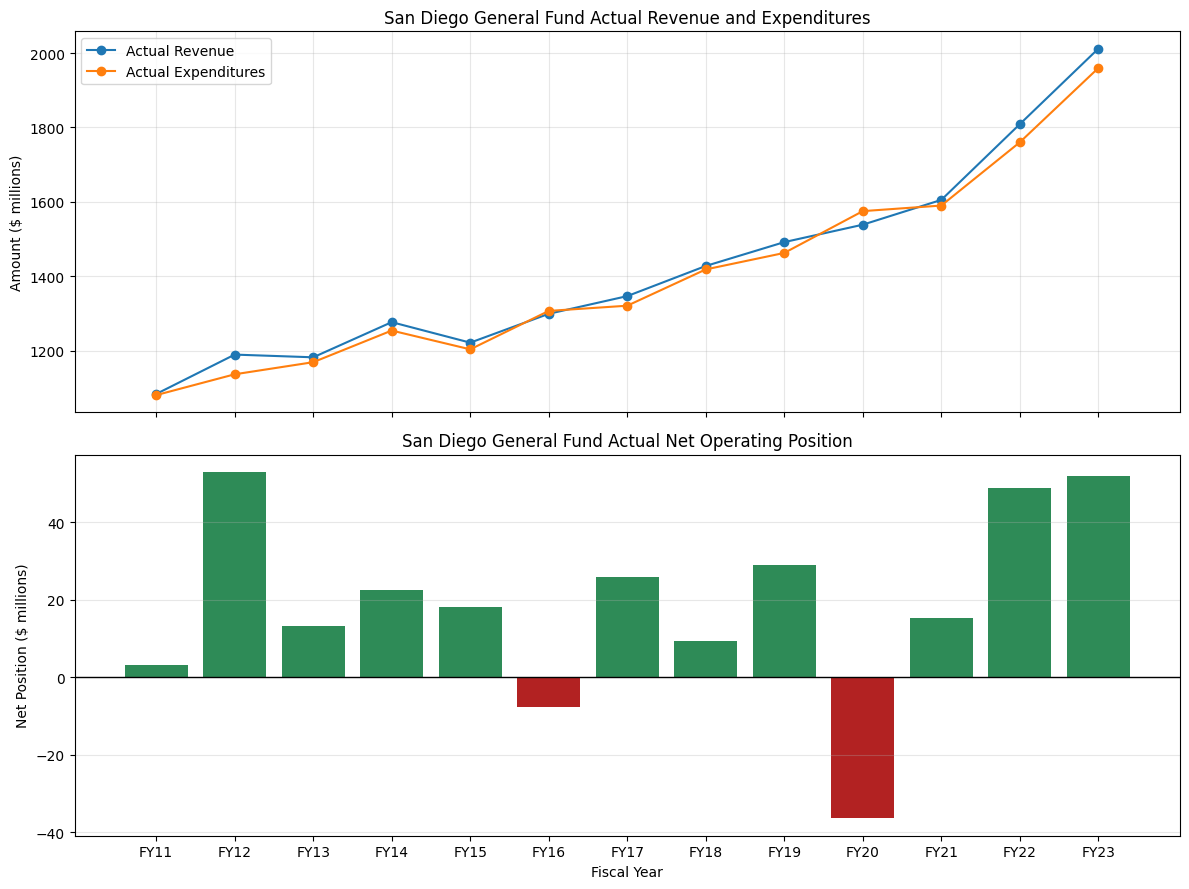

In [54]:
import matplotlib.pyplot as plt

# Create two charts:
# 1. Actual revenue versus actual expenditures
# 2. Actual net operating position

fig, axes = plt.subplots(
    2,
    1,
    figsize=(12, 9),
    sharex=True
)

# Convert amounts to millions for easier reading
years = all_year_trend["fiscal_year_std"]
revenue_millions = (
    all_year_trend["actual_total_revenue"] / 1_000_000
)
expenditure_millions = (
    all_year_trend["actual_total_expenditure"] / 1_000_000
)
net_position_millions = (
    all_year_trend["actual_net_position"] / 1_000_000
)

# Chart 1: Actual revenue versus expenditures
axes[0].plot(
    years,
    revenue_millions,
    marker="o",
    label="Actual Revenue"
)

axes[0].plot(
    years,
    expenditure_millions,
    marker="o",
    label="Actual Expenditures"
)

axes[0].set_title(
    "San Diego General Fund Actual Revenue and Expenditures"
)

axes[0].set_ylabel("Amount ($ millions)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Chart 2: Actual net operating position
axes[1].bar(
    years,
    net_position_millions,
    color=[
        "firebrick" if value < 0 else "seagreen"
        for value in net_position_millions
    ]
)

axes[1].axhline(
    0,
    color="black",
    linewidth=1
)

axes[1].set_title(
    "San Diego General Fund Actual Net Operating Position"
)

axes[1].set_ylabel("Net Position ($ millions)")
axes[1].set_xlabel("Fiscal Year")
axes[1].grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [55]:
# Create a simplified report-ready trend table

final_trend_summary = all_year_trend[
    [
        "fiscal_year_std",
        "budget_net_position",
        "actual_net_position",
        "actual_total_revenue",
        "actual_total_expenditure",
        "actual_revenue_growth_percent",
        "actual_expenditure_growth_percent",
        "actual_status"
    ]
].copy()

# Convert dollar amounts to millions
amount_columns = [
    "budget_net_position",
    "actual_net_position",
    "actual_total_revenue",
    "actual_total_expenditure"
]

for column in amount_columns:
    final_trend_summary[column] = (
        final_trend_summary[column] / 1_000_000
    )

# Round values for readability
final_trend_summary = final_trend_summary.round(
    {
        "budget_net_position": 2,
        "actual_net_position": 2,
        "actual_total_revenue": 2,
        "actual_total_expenditure": 2,
        "actual_revenue_growth_percent": 2,
        "actual_expenditure_growth_percent": 2
    }
)

display(final_trend_summary)

,fiscal_year_std,budget_net_position,actual_net_position,actual_total_revenue,actual_total_expenditure,actual_revenue_growth_percent,actual_expenditure_growth_percent,actual_status
0,FY11,0.00,3.02,1083.18,1080.16,NaN,NaN,Surplus
1,FY12,-1.79,52.95,1189.11,1136.15,9.78,5.18,Surplus
2,FY13,-12.73,13.15,1181.85,1168.70,-0.61,2.86,Surplus
3,FY14,-22.44,22.61,1276.38,1253.77,8.00,7.28,Surplus
4,FY15,-13.87,17.97,1221.22,1203.25,-4.32,-4.03,Surplus
5,FY16,-6.16,-7.77,1298.82,1306.58,6.35,8.59,Deficit
6,FY17,-8.02,25.82,1346.44,1320.62,3.67,1.07,Surplus
7,FY18,-26.08,9.30,1427.50,1418.20,6.02,7.39,Surplus
8,FY19,-22.69,29.05,1491.63,1462.57,4.49,3.13,Surplus
9,FY20,-40.76,-36.47,1538.50,1574.97,3.14,7.69,Deficit


**Recurring Financial Pressure**

In [56]:
# Standardize recurring expenditure pressures

recurring_expenditure = (
    recurring_account_group_pressure
    .rename(
        columns={
            "years_over_budget": "years_with_pressure",
            "total_overage": "total_pressure",
            "average_overage": "average_pressure",
            "largest_single_year_overage": "largest_single_year_pressure"
        }
    )
    .assign(
        pressure_type="Expenditure overage"
    )
)

recurring_expenditure = recurring_expenditure[
    [
        "account_group",
        "pressure_type",
        "years_with_pressure",
        "total_pressure",
        "average_pressure",
        "largest_single_year_pressure"
    ]
]

In [57]:
# Standardize recurring revenue pressures

recurring_revenue = (
    recurring_revenue_shortfalls
    .assign(
        pressure_type="Revenue shortfall",
        total_pressure=lambda df: df["total_shortfall"].abs(),
        average_pressure=lambda df: df["average_shortfall"].abs(),
        largest_single_year_pressure=lambda df:
            df["largest_single_year_shortfall"].abs(),
        years_with_pressure=lambda df: df["years_below_budget"]
    )
)

recurring_revenue = recurring_revenue[
    [
        "account_group",
        "pressure_type",
        "years_with_pressure",
        "total_pressure",
        "average_pressure",
        "largest_single_year_pressure"
    ]
]

In [58]:
# Combine recurring revenue and expenditure pressures

recurring_pressure_summary = pd.concat(
    [
        recurring_expenditure,
        recurring_revenue
    ],
    ignore_index=True
)

# Convert dollar amounts to millions
recurring_pressure_summary["total_pressure_millions"] = (
    recurring_pressure_summary["total_pressure"] / 1_000_000
)

recurring_pressure_summary["average_pressure_millions"] = (
    recurring_pressure_summary["average_pressure"] / 1_000_000
)

recurring_pressure_summary["largest_single_year_pressure_millions"] = (
    recurring_pressure_summary["largest_single_year_pressure"]
    / 1_000_000
)

# Rank by consistency first, then total dollar impact
recurring_pressure_summary = (
    recurring_pressure_summary
    .sort_values(
        [
            "years_with_pressure",
            "total_pressure"
        ],
        ascending=[False, False]
    )
)

display(
    recurring_pressure_summary[
        [
            "account_group",
            "pressure_type",
            "years_with_pressure",
            "total_pressure_millions",
            "average_pressure_millions",
            "largest_single_year_pressure_millions"
        ]
    ].head(20)
)

,account_group,pressure_type,years_with_pressure,total_pressure_millions,average_pressure_millions,largest_single_year_pressure_millions
21,Transient Occupancy Taxes,Revenue shortfall,13,1073.372174,82.567090,128.175999
0,Medicare,Expenditure overage,13,10.660320,0.820025,1.415194
22,Charges for Current Services,Revenue shortfall,12,202.847254,16.903938,36.822747
27,CATV,Revenue shortfall,11,20.770901,1.888264,6.329440
32,Municipal Court,Revenue shortfall,10,8.850311,0.885031,1.512270
1,Transfers Out,Expenditure overage,8,89.863803,11.232975,31.917285
2,Internal Contracts & Services,Expenditure overage,8,27.032302,3.379038,7.572847
3,Workers' Compensation,Expenditure overage,8,14.932746,1.866593,6.920236
23,Transfers In,Revenue shortfall,7,68.950014,9.850002,23.364788
30,Other Licenses and Permits,Revenue shortfall,7,9.609995,1.372856,2.579023


In [59]:
# Top recurring revenue shortfalls

top_recurring_revenue = (
    recurring_pressure_summary[
        recurring_pressure_summary["pressure_type"] == "Revenue shortfall"
    ]
    .sort_values(
        "total_pressure_millions",
        ascending=False
    )
    .head(5)
)

display(top_recurring_revenue)

,account_group,pressure_type,years_with_pressure,total_pressure,average_pressure,largest_single_year_pressure,total_pressure_millions,average_pressure_millions,largest_single_year_pressure_millions
21,Transient Occupancy Taxes,Revenue shortfall,13,1.073372e+09,8.256709e+07,128175999.0,1073.372174,82.567090,128.175999
22,Charges for Current Services,Revenue shortfall,12,2.028473e+08,1.690394e+07,36822747.0,202.847254,16.903938,36.822747
23,Transfers In,Revenue shortfall,7,6.895001e+07,9.850002e+06,23364788.0,68.950014,9.850002,23.364788
24,Sales Tax,Revenue shortfall,6,3.438022e+07,5.730037e+06,15048489.0,34.380223,5.730037,15.048489
25,SDG&E,Revenue shortfall,4,2.672112e+07,6.680280e+06,18385574.0,26.721122,6.680281,18.385574


In [60]:
# Top recurring expenditure overages

top_recurring_expenditures = (
    recurring_pressure_summary[
        recurring_pressure_summary["pressure_type"] == "Expenditure overage"
    ]
    .sort_values(
        "total_pressure_millions",
        ascending=False
    )
    .head(5)
)

display(top_recurring_expenditures)

,account_group,pressure_type,years_with_pressure,total_pressure,average_pressure,largest_single_year_pressure,total_pressure_millions,average_pressure_millions,largest_single_year_pressure_millions
1,Transfers Out,Expenditure overage,8,89863803.0,1.123298e+07,31917285.0,89.863803,11.232975,31.917285
2,Internal Contracts & Services,Expenditure overage,8,27032302.0,3.379038e+06,7572847.0,27.032302,3.379038,7.572847
14,External Contracts & Services,Expenditure overage,1,19438340.0,1.943834e+07,19438340.0,19.438340,19.438340,19.438340
3,Workers' Compensation,Expenditure overage,8,14932746.0,1.866593e+06,6920236.0,14.932746,1.866593,6.920236
0,Medicare,Expenditure overage,13,10660320.0,8.200246e+05,1415194.0,10.660320,0.820025,1.415194


In [61]:
# Keep only expenditure groups that exceeded budget
# in at least two fiscal years.

top_recurring_expenditures = (
    recurring_pressure_summary[
        (recurring_pressure_summary["pressure_type"] == "Expenditure overage")
        & (recurring_pressure_summary["years_with_pressure"] >= 2)
    ]
    .sort_values(
        "total_pressure_millions",
        ascending=False
    )
    .head(5)
)

display(top_recurring_expenditures)

,account_group,pressure_type,years_with_pressure,total_pressure,average_pressure,largest_single_year_pressure,total_pressure_millions,average_pressure_millions,largest_single_year_pressure_millions
1,Transfers Out,Expenditure overage,8,89863803.0,1.123298e+07,31917285.0,89.863803,11.232975,31.917285
2,Internal Contracts & Services,Expenditure overage,8,27032302.0,3.379038e+06,7572847.0,27.032302,3.379038,7.572847
3,Workers' Compensation,Expenditure overage,8,14932746.0,1.866593e+06,6920236.0,14.932746,1.866593,6.920236
0,Medicare,Expenditure overage,13,10660320.0,8.200246e+05,1415194.0,10.660320,0.820025,1.415194
4,Long-Term Disability,Expenditure overage,6,4758976.0,7.931627e+05,2233783.0,4.758976,0.793163,2.233783


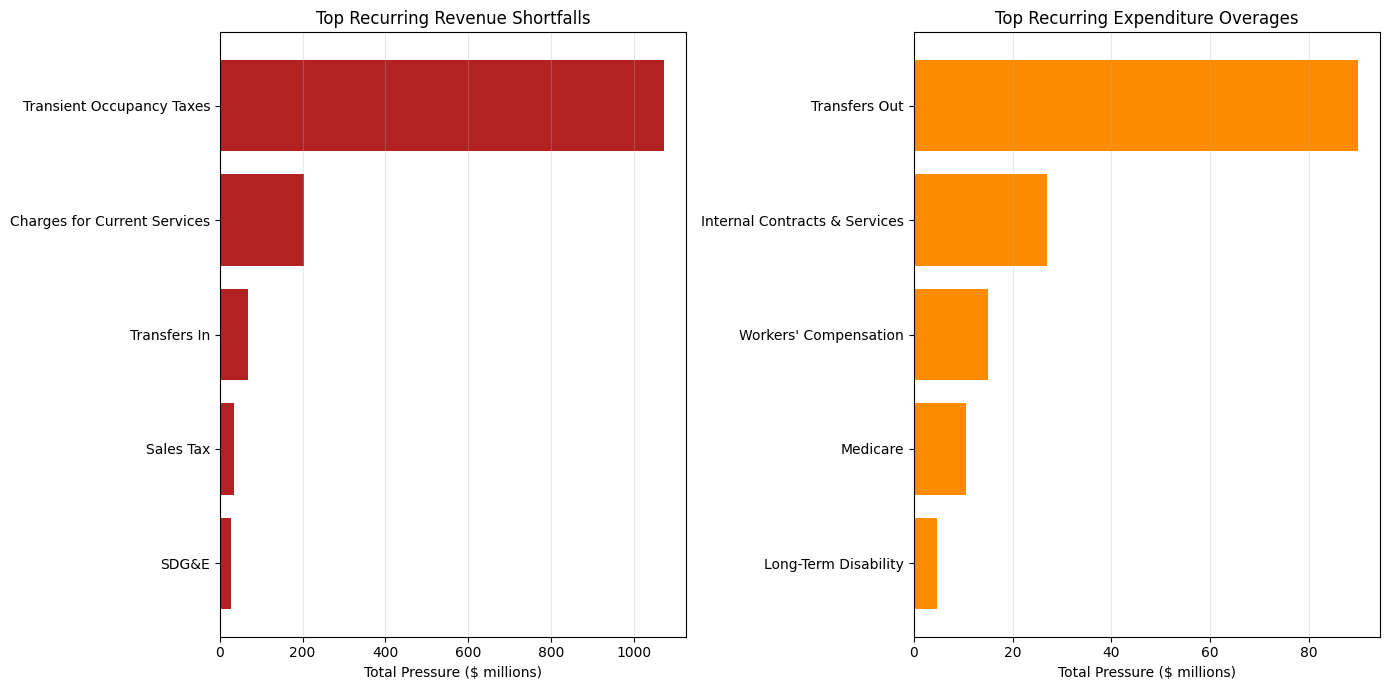

In [62]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 7)
)

# Recurring revenue shortfalls
axes[0].barh(
    top_recurring_revenue["account_group"],
    top_recurring_revenue["total_pressure_millions"],
    color="firebrick"
)

axes[0].set_title("Top Recurring Revenue Shortfalls")
axes[0].set_xlabel("Total Pressure ($ millions)")
axes[0].invert_yaxis()
axes[0].grid(axis="x", alpha=0.3)

# Recurring expenditure overages
axes[1].barh(
    top_recurring_expenditures["account_group"],
    top_recurring_expenditures["total_pressure_millions"],
    color="darkorange"
)

axes[1].set_title("Top Recurring Expenditure Overages")
axes[1].set_xlabel("Total Pressure ($ millions)")
axes[1].invert_yaxis()
axes[1].grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

**FY16 and FY20 Case Studies**

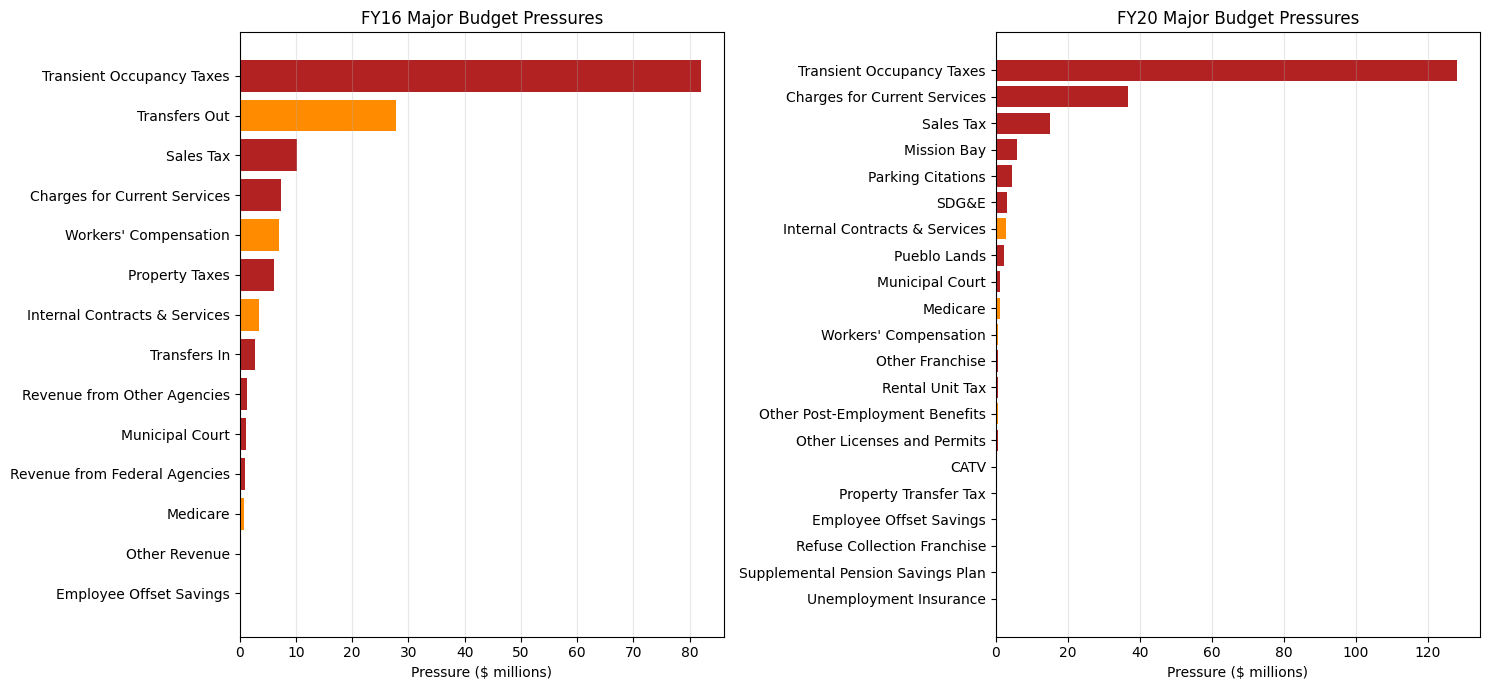

In [63]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 7),
    sharex=False
)

for axis, year in zip(axes, ["FY16", "FY20"]):

    year_data = (
        deficit_pressures[
            deficit_pressures["fiscal_year_std"] == year
        ]
        .sort_values("pressure_amount")
    )

    colors = [
        "firebrick"
        if pressure_type == "Revenue shortfall"
        else "darkorange"
        for pressure_type in year_data["pressure_type"]
    ]

    axis.barh(
        year_data["account_group"],
        year_data["pressure_amount"] / 1_000_000,
        color=colors
    )

    axis.set_title(f"{year} Major Budget Pressures")
    axis.set_xlabel("Pressure ($ millions)")
    axis.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

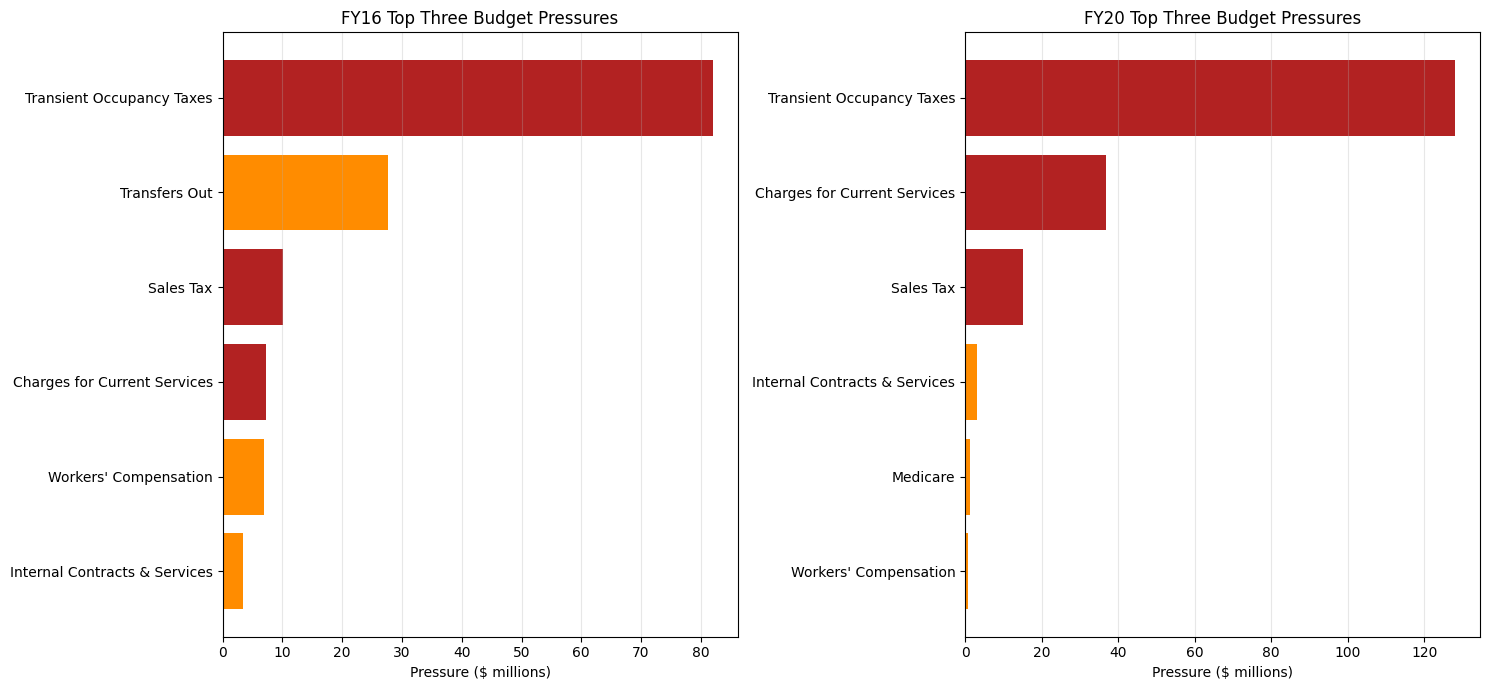

In [64]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 7)
)

for axis, year in zip(axes, ["FY16", "FY20"]):

    year_data = (
        top_three_pressures[
            top_three_pressures["fiscal_year_std"] == year
        ]
        .sort_values("pressure_amount")
    )

    colors = [
        "firebrick"
        if pressure_type == "Revenue shortfall"
        else "darkorange"
        for pressure_type in year_data["pressure_type"]
    ]

    axis.barh(
        year_data["account_group"],
        year_data["pressure_amount"] / 1_000_000,
        color=colors
    )

    axis.set_title(f"{year} Top Three Budget Pressures")
    axis.set_xlabel("Pressure ($ millions)")
    axis.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

**Department Pressure**

In [65]:
# Analyze all General Fund expenditure activity by department

actual_department = (
    actual_general_full[
        actual_general_full["financial_category"] == "Expenditure"
    ]
    .groupby(
        ["fiscal_year_std", "dept_name"],
        as_index=False,
        observed=True
    )
    .agg(
        actual_total=("amount", "sum")
    )
)

budget_department = (
    budget_general_full[
        budget_general_full["financial_category"] == "Expenditure"
    ]
    .groupby(
        ["fiscal_year_std", "dept_name"],
        as_index=False,
        observed=True
    )
    .agg(
        budget_total=("amount", "sum")
    )
)

# Compare all departmental budget and actual expenditure totals

department_summary_all = budget_department.merge(
    actual_department,
    on=["fiscal_year_std", "dept_name"],
    how="outer",
    indicator=True
)

# Treat a missing side as no recorded amount at that department-year level
department_summary_all["budget_total"] = (
    department_summary_all["budget_total"].fillna(0)
)

department_summary_all["actual_total"] = (
    department_summary_all["actual_total"].fillna(0)
)

department_summary_all["variance_total"] = (
    department_summary_all["actual_total"]
    - department_summary_all["budget_total"]
)

display(department_summary_all.head())

,fiscal_year_std,dept_name,budget_total,actual_total,_merge,variance_total
0,FY11,Assistant Chief Operating Officer,311820.0,303944.0,both,-7876.0
1,FY11,Business Office,1157683.0,0.0,left_only,-1157683.0
2,FY11,Chief Financial Officer,913633.0,684105.0,both,-229528.0
3,FY11,City Attorney,41884483.0,40401106.0,both,-1483377.0
4,FY11,City Clerk,4763463.0,4491908.0,both,-271555.0


In [66]:
# Rank departments by total expenditure overage

department_totals = (
    department_summary_all[
        department_summary_all["variance_total"] > 0
    ]
    .groupby(
        "dept_name",
        as_index=False
    )
    .agg(
        years_over_budget=("fiscal_year_std", "nunique"),
        total_overage=("variance_total", "sum"),
        average_overage=("variance_total", "mean"),
        largest_single_year_overage=("variance_total", "max")
    )
    .sort_values(
        "total_overage",
        ascending=False
    )
)

display(department_totals.head(20))

,dept_name,years_over_budget,total_overage,average_overage,largest_single_year_overage
23,Fire-Rescue,13,146980209.0,1.130617e+07,38916117.0
5,Citywide Expenses,6,112007409.0,1.866790e+07,34228536.0
37,Police,11,106701149.0,9.700104e+06,22604527.0
18,Economic Development,3,8678298.0,2.892766e+06,4610425.0
44,Transportation,3,8020447.0,2.673482e+06,4187925.0
17,Development Services,2,7939022.0,3.969511e+06,7844552.0
34,Parks & Recreation,2,7412099.0,3.706050e+06,4950803.0
2,City Attorney,5,7365430.0,1.473086e+06,3060561.0
43,Stormwater,3,5268522.0,1.756174e+06,4403834.0
29,Neighborhood Services,2,3858025.0,1.929012e+06,3615695.0


In [67]:
# Focus on departments that exceeded their expenditure budgets
# in at least two fiscal years.

recurring_departments_all = (
    department_totals[
        department_totals["years_over_budget"] >= 2
    ]
    .sort_values(
        [
            "years_over_budget",
            "total_overage"
        ],
        ascending=[False, False]
    )
)

display(recurring_departments_all)

,dept_name,years_over_budget,total_overage,average_overage,largest_single_year_overage
23,Fire-Rescue,13,146980209.0,1.130617e+07,38916117.0
37,Police,11,106701149.0,9.700104e+06,22604527.0
5,Citywide Expenses,6,112007409.0,1.866790e+07,34228536.0
36,Personnel,6,2526008.0,4.210013e+05,1285196.0
28,Library,6,2356792.0,3.927987e+05,763626.0
32,Office of the Chief Operating Officer,6,979651.0,1.632752e+05,696211.0
2,City Attorney,5,7365430.0,1.473086e+06,3060561.0
35,Performance & Analytics,5,2889924.0,5.779848e+05,914190.0
38,Public Utilities,5,920228.0,1.840456e+05,379646.0
0,Assistant Chief Operating Officer,4,569789.0,1.424472e+05,283159.0


In [68]:
# Identify the departments with the largest expenditure overages
# in each fiscal year

top_departments_by_year = (
    department_summary_all[
        department_summary_all["variance_total"] > 0
    ]
    .sort_values(
        ["fiscal_year_std", "variance_total"],
        ascending=[True, False]
    )
    .groupby("fiscal_year_std", observed=True)
    .head(5)
    .reset_index(drop=True)
)

display(top_departments_by_year)

,fiscal_year_std,dept_name,budget_total,actual_total,_merge,variance_total
0,FY11,Police,384844349.0,395859865.0,both,11015516.0
1,FY11,Fire-Rescue,181901923.0,188587532.0,both,6685609.0
2,FY11,Performance & Analytics,0.0,909652.0,right_only,909652.0
3,FY11,Environmental Services,32561646.0,33466415.0,both,904769.0
4,FY11,Stormwater,35183439.0,35928827.0,both,745388.0
...,...,...,...,...,...,...
60,FY23,Fire-Rescue,310961654.0,349877771.0,both,38916117.0
61,FY23,Stormwater,66457083.0,70860917.0,both,4403834.0
62,FY23,Police,584706166.0,588906166.0,both,4200000.0
63,FY23,Transportation,93646966.0,97834891.0,both,4187925.0


In [69]:
# Keep only department-years with both budget and actual values
# so unmatched records are not treated as budget overages

department_summary_matched = (
    department_summary_all[
        department_summary_all["_merge"] == "both"
    ]
    .copy()
)

# Calculate department overages using matched records only
department_summary_matched["variance_total"] = (
    department_summary_matched["actual_total"]
    - department_summary_matched["budget_total"]
)

# Show the largest departmental overages in FY16 and FY20
department_deficit_years = (
    department_summary_matched[
        department_summary_matched["fiscal_year_std"].isin(["FY16", "FY20"])
        & (department_summary_matched["variance_total"] > 0)
    ]
    .sort_values(
        ["fiscal_year_std", "variance_total"],
        ascending=[True, False]
    )
)

display(department_deficit_years)

,fiscal_year_std,dept_name,budget_total,actual_total,_merge,variance_total
238,FY16,Citywide Expenses,89609808.0,123838344.0,both,34228536.0
258,FY16,Fire-Rescue,229258665.0,235634964.0,both,6376299.0
233,FY16,City Attorney,46709688.0,47435011.0,both,725323.0
269,FY16,Personnel,7434136.0,7809276.0,both,375140.0
235,FY16,City Comptroller,11111938.0,11199418.0,both,87480.0
255,FY16,Ethics Commission,1047777.0,1130722.0,both,82945.0
240,FY16,Council Administration,2059166.0,2140673.0,both,81507.0
275,FY16,Smart & Sustainable Communities,857024.0,894181.0,both,37157.0
264,FY16,Office of the Chief Operating Officer,1043163.0,1061523.0,both,18360.0
259,FY16,Human Resources,3268272.0,3281964.0,both,13692.0


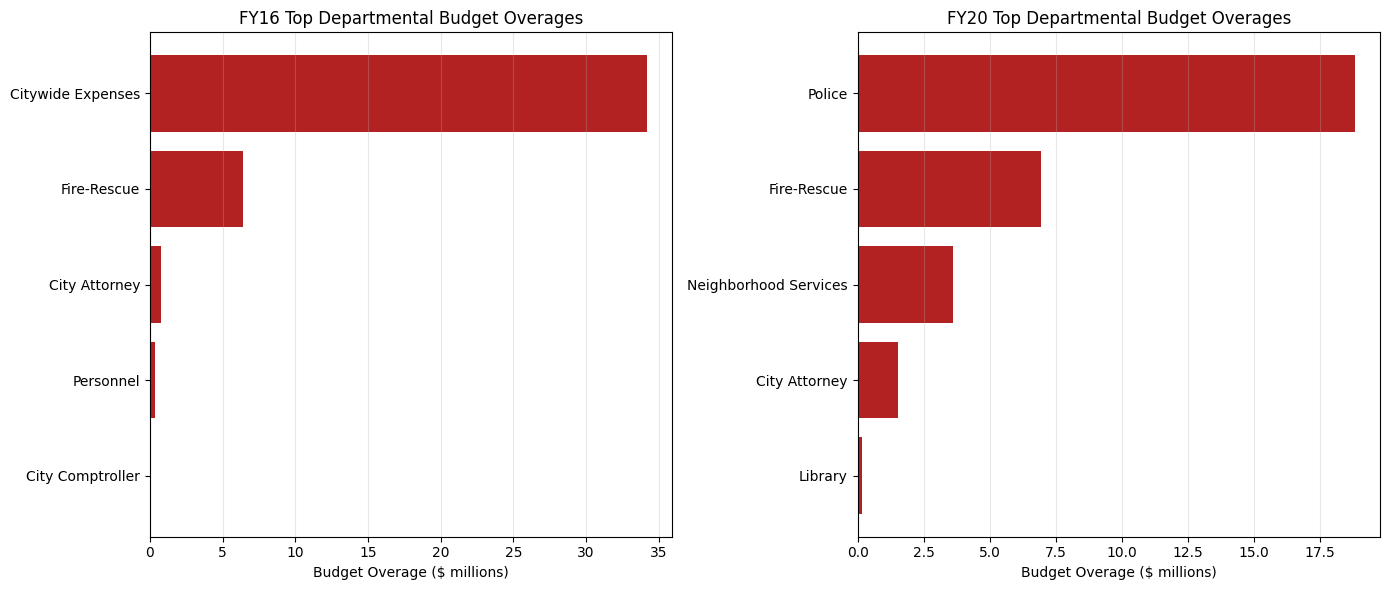

In [70]:
import matplotlib.pyplot as plt

# Select the five largest departmental overages in each deficit year
top_department_pressures = (
    department_deficit_years
    .groupby("fiscal_year_std", observed=True)
    .head(5)
    .copy()
)

# Convert dollar amounts to millions
top_department_pressures["variance_millions"] = (
    top_department_pressures["variance_total"] / 1_000_000
)

# Create side-by-side charts
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, year in zip(axes, ["FY16", "FY20"]):
    data = (
        top_department_pressures[
            top_department_pressures["fiscal_year_std"] == year
        ]
        .sort_values("variance_millions")
    )

    ax.barh(
        data["dept_name"],
        data["variance_millions"],
        color="firebrick"
    )

    ax.set_title(f"{year} Top Departmental Budget Overages")
    ax.set_xlabel("Budget Overage ($ millions)")
    ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

**Transfers and Accounting structure**

In [71]:
# SECTION 5: Analyze Transfers In and Transfers Out

# Create an account-number-to-account-group reference mapping
account_group_map = (
    analysis_df[
        ["account_number", "account_group"]
    ]
    .dropna(subset=["account_number", "account_group"])
    .drop_duplicates()
    .copy()
)

# Make sure account numbers have the same data type
account_group_map["account_number"] = pd.to_numeric(
    account_group_map["account_number"],
    errors="coerce"
)

actual_general_full["account_number"] = pd.to_numeric(
    actual_general_full["account_number"],
    errors="coerce"
)

budget_general_full["account_number"] = pd.to_numeric(
    budget_general_full["account_number"],
    errors="coerce"
)

# Attach account groups to the complete actual dataset
actual_general_full_with_groups = actual_general_full.merge(
    account_group_map,
    on="account_number",
    how="left"
)

# Attach account groups to the complete budget dataset
budget_general_full_with_groups = budget_general_full.merge(
    account_group_map,
    on="account_number",
    how="left"
)

# Keep only Transfers In and Transfers Out
transfer_groups = ["Transfers In", "Transfers Out"]

actual_transfers = actual_general_full_with_groups[
    actual_general_full_with_groups["account_group"].isin(transfer_groups)
].copy()

budget_transfers = budget_general_full_with_groups[
    budget_general_full_with_groups["account_group"].isin(transfer_groups)
].copy()

# Summarize actual transfers
actual_transfer_summary = (
    actual_transfers
    .groupby(
        ["fiscal_year_std", "account_group"],
        as_index=False,
        observed=True
    )
    .agg(actual_total=("amount", "sum"))
)

# Summarize budgeted transfers
budget_transfer_summary = (
    budget_transfers
    .groupby(
        ["fiscal_year_std", "account_group"],
        as_index=False,
        observed=True
    )
    .agg(budget_total=("amount", "sum"))
)

# Merge budget and actual transfer totals
transfer_summary = pd.merge(
    budget_transfer_summary,
    actual_transfer_summary,
    on=["fiscal_year_std", "account_group"],
    how="outer"
)

# Replace missing totals with zero
transfer_summary["budget_total"] = (
    transfer_summary["budget_total"].fillna(0)
)

transfer_summary["actual_total"] = (
    transfer_summary["actual_total"].fillna(0)
)

# Calculate the variance
transfer_summary["variance_total"] = (
    transfer_summary["actual_total"]
    - transfer_summary["budget_total"]
)

# Display the transfer results
display(
    transfer_summary.sort_values(
        ["fiscal_year_std", "account_group"]
    )
)

,fiscal_year_std,account_group,budget_total,actual_total,variance_total
0,FY11,Transfers In,111442403,65288917,-46153486
1,FY11,Transfers Out,52357895,29364731,-22993164
2,FY12,Transfers In,100886186,91567369,-9318817
3,FY12,Transfers Out,51528472,69703033,18174561
4,FY13,Transfers In,73421129,87575864,14154735
5,FY13,Transfers Out,67347874,70541523,3193649
6,FY14,Transfers In,87149543,94619420,7469877
7,FY14,Transfers Out,61004542,51915599,-9088943
8,FY15,Transfers In,77133211,76417885,-715326
9,FY15,Transfers Out,69046098,74035831,4989733


In [72]:
# Calculate the net effect of transfers by fiscal year

transfer_position = (
    transfer_summary
    .pivot(
        index="fiscal_year_std",
        columns="account_group",
        values=["budget_total", "actual_total"]
    )
    .fillna(0)
)

# Flatten the multi-level column names
transfer_position.columns = [
    "_".join(column).lower().replace(" ", "_")
    for column in transfer_position.columns
]

transfer_position = transfer_position.reset_index()

# Calculate net transfers:
# Transfers In minus Transfers Out
transfer_position["budget_net_transfer_effect"] = (
    transfer_position["budget_total_transfers_in"]
    - transfer_position["budget_total_transfers_out"]
)

transfer_position["actual_net_transfer_effect"] = (
    transfer_position["actual_total_transfers_in"]
    - transfer_position["actual_total_transfers_out"]
)

# Calculate how much transfers differed from the budget
transfer_position["net_transfer_variance"] = (
    transfer_position["actual_net_transfer_effect"]
    - transfer_position["budget_net_transfer_effect"]
)

display(transfer_position)

,fiscal_year_std,budget_total_transfers_in,budget_total_transfers_out,actual_total_transfers_in,actual_total_transfers_out,budget_net_transfer_effect,actual_net_transfer_effect,net_transfer_variance
0,FY11,111442403,52357895,65288917,29364731,59084508,35924186,-23160322
1,FY12,100886186,51528472,91567369,69703033,49357714,21864336,-27493378
2,FY13,73421129,67347874,87575864,70541523,6073255,17034341,10961086
3,FY14,87149543,61004542,94619420,51915599,26145001,42703821,16558820
4,FY15,77133211,69046098,76417885,74035831,8087113,2382054,-5705059
5,FY16,93632574,71030123,79979691,88493749,22602451,-8514058,-31116509
6,FY17,91388871,61350111,80598432,52541466,30038760,28056966,-1981794
7,FY18,117789072,81200582,118110325,62937375,36588490,55172950,18584460
8,FY19,90208443,63079706,76709482,63855906,27128737,12853576,-14275161
9,FY20,104074874,86131863,177052176,67853160,17943011,109199016,91256005


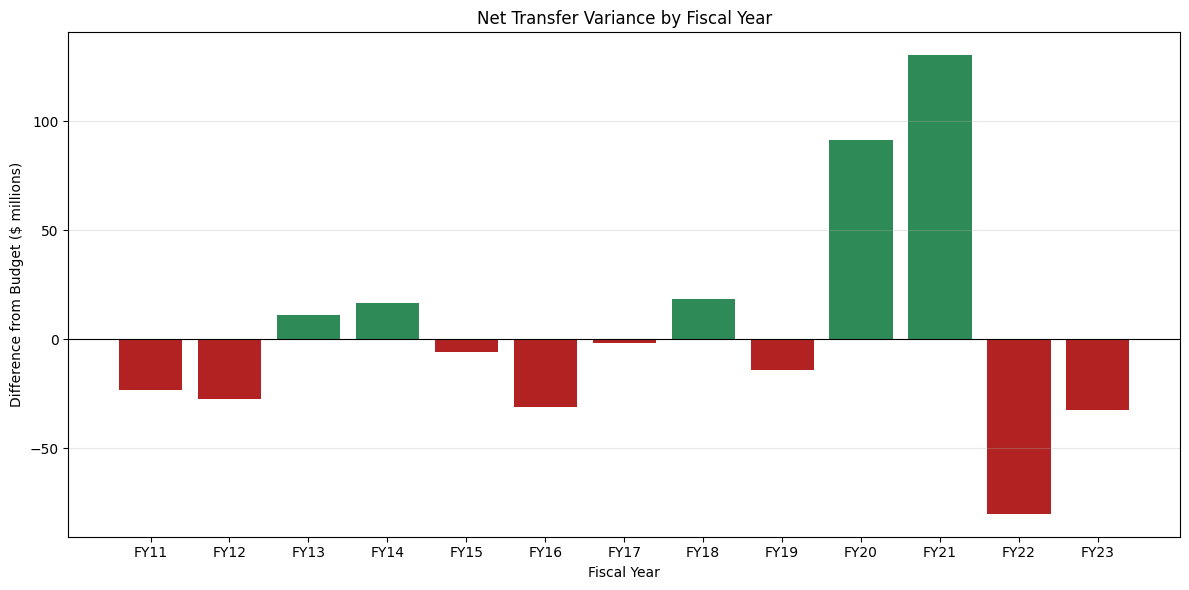

In [73]:
import matplotlib.pyplot as plt

transfer_chart = transfer_position.copy()

transfer_chart["net_transfer_variance_millions"] = (
    transfer_chart["net_transfer_variance"] / 1_000_000
)

colors = [
    "seagreen" if value >= 0 else "firebrick"
    for value in transfer_chart["net_transfer_variance_millions"]
]

plt.figure(figsize=(12, 6))

plt.bar(
    transfer_chart["fiscal_year_std"],
    transfer_chart["net_transfer_variance_millions"],
    color=colors
)

plt.axhline(0, color="black", linewidth=0.8)
plt.title("Net Transfer Variance by Fiscal Year")
plt.xlabel("Fiscal Year")
plt.ylabel("Difference from Budget ($ millions)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [74]:
!find /content -type f -name "*.db"

/content/.config/default_configs.db
/content/.config/hidden_gcloud_config_universe_descriptor_data_cache_configs.db
/content/drive/MyDrive/stat420_budget.db
